# Pipeline Prediksi Kurs USD/IDR Bebas Kebocoran: Frozen BERT + FinBERT + BERTopic + Classifier Arah + Bi-LSTM

Notebook ini mengimplementasikan pipeline **end-to-end bebas data leakage** (*split dari awal* secara kronologis `70% Train / 15% Val / 15% Test`):

1. **Split Kronologis di Awal**: Semua *fitting* (PCA, BERTopic, UMAP, `StandardScaler`, ambang kuantil sentimen tinggi, Classifier Stage 1 + OOF Train, dan Bi-LSTM) dilakukan **hanya pada Train set**.
2. **Data Teks — Frozen BERT Title Embedding + PCA**:
   - Memecah `all_title` harian per artikel (`" | "`), mengekstrak *embedding* `bert-base-uncased` (bobot dibekukan / *freeze*, tanpa *fine-tuning*), merata-ratakan per hari, lalu mereduksi dimensinya dengan **PCA** (fit di Train).
3. **Analisis Sentimen & Polaritas BERT (Logika Kurs Indonesia)**:
   - Menggunakan `ProsusAI/finbert` (bobot dibekukan) untuk menghitung probabilitas $(P_{	ext{pos}}, P_{	ext{neg}}, P_{	ext{neu}})$ dan polaritas kontinu:
     $$\text{sent\_polarity} = P_{\text{pos}} - P_{\text{neg}} \in [-1, +1], \qquad \text{kurs\_pressure} = -\text{sent\_polarity} = P_{\text{neg}} - P_{\text{pos}} \in [-1, +1]$$
   - **Logika Kurs Indonesia (berita internasional tidak menggerakkan USD secara langsung di sini, melainkan menekan/menguatkan Rupiah)**:
     - Berita internasional **Negatif** ($\text{sent\_polarity} < 0$) $\Rightarrow \text{kurs\_pressure} > 0 \Rightarrow$ **Kurs Rupiah Naik** (melemah).
     - Berita internasional **Positif** ($\text{sent\_polarity} > 0$) $\Rightarrow \text{kurs\_pressure} < 0 \Rightarrow$ **Kurs Rupiah Turun** (menguat).
     - Berita **Netral**: tetap mempertahankan **kecenderungan** kontinu, misalnya $\text{kurs\_pressure} = -0.10$ berarti cenderung **menurun tapi sedikit**.
4. **Topic Modelling BERTopic + Reduksi Dimensi (UMAP & PCA)**:
   - Fit BERTopic (`all-MiniLM-L6-v2` + UMAP 5D + HDBSCAN) **hanya pada hari berberita di Train set**, transform ke Val & Test, lalu reduksi dimensi probabilitas topik & embedding menggunakan **UMAP 2D** dan **PCA** (fit di Train).
5. **Stage 1 — Classifier Arah Return + Fitur `Sentimen × Arah` (Tandai Naik/Turun Sentimen Tinggi)**:
   - Menggabungkan `BERT Title PCA` + `Sentimen & Polaritas BERT` + `BERTopic tereduksi` untuk melatih **Classifier Arah Return** (dengan **5-Fold OOF di dalam Train** agar bebas overfitting saat dipakai di Stage 2).
   - Membentuk fitur interaksi **`sent_x_dir`** dan menandai hari **Naik Sentimen Tinggi** & **Turun Sentimen Tinggi** menggunakan ambang kuantil Train set.
6. **Stage 2 — Fitur Time Series + Model Bi-LSTM**:
   - Menggabungkan hasil Stage 1 dengan fitur *time series* (*strictly causal* $\le t-1$: lagged return, volatilitas rolling, deviasi MA, RSI, streak, spread, hari perdagangan) lalu melatih **Bi-LSTM** untuk memprediksi `log_return` dan arah kurs.


## 1. Setup Lingkungan & Seed Deterministik


In [1]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["USE_TF"] = "0"

import gc
import re
import copy
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification
from sentence_transformers import SentenceTransformer

from umap import UMAP
from hdbscan import HDBSCAN
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression, Ridge, ElasticNet
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier,
    GradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

warnings.filterwarnings("ignore")

SEED = 42
def set_seed(seed: int = SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.titlesize": 11.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 9.5,
})
sns.set_style("whitegrid")

print(f"Device aktif : {DEVICE}")
print(f"PyTorch      : {torch.__version__}")


C:\Users\grace\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device aktif : cpu
PyTorch      : 2.13.0+cpu


## 2. Pemuatan Dataset & Split Kronologis di Awal (Zero Leakage)

Dataset `merged_data_clean.csv` diurutkan kronologis, dihitung target `log_ret` dan arah `y_dir` (`1` = Kurs Naik, `0` = Kurs Turun), lalu **langsung di-split 70% Train / 15% Val / 15% Test di awal** sebelum transformasi fitur apa pun.


In [2]:
DATA_CANDIDATES = [
    Path("data/processed/merged_data_clean.csv"),
    Path("../data/processed/merged_data_clean.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Tidak menemukan data/processed/merged_data_clean.csv!")

df = pd.read_csv(DATA_PATH)
date_col = "Tanggal_dt" if "Tanggal_dt" in df.columns else "tanggal"
df[date_col] = pd.to_datetime(df[date_col])
df = df.sort_values(date_col).reset_index(drop=True)

# Kurs tengah BI
if "rate_mid" not in df.columns:
    df["rate_mid"] = (df["Kurs Jual"] + df["Kurs Beli"]) / 2.0

# Target return harian dan arah (1 = kurs USD/IDR naik, 0 = turun)
df["log_ret"] = np.log(df["rate_mid"] / df["rate_mid"].shift(1))
df = df.dropna(subset=["log_ret"]).reset_index(drop=True)
df["y_dir"] = (df["log_ret"] > 0).astype(int)

def clean_text_keep_case(text) -> str:
    if not isinstance(text, str):
        return ""
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)
    text = re.sub(r"<.*?>", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df["title_clean"] = df["all_title"].fillna("").apply(clean_text_keep_case)
df["norm_clean"] = df["all_normalized_text"].fillna("").apply(clean_text_keep_case)
df["has_news"] = (df["news_count"].fillna(0) > 0).astype(int)

# SPLIT KRONOLOGIS DI AWAL (70% Train / 15% Val / 15% Test)
n_total = len(df)
train_end_idx = int(n_total * 0.70)
val_end_idx = int(n_total * 0.85)

df["split"] = "test"
df.loc[:train_end_idx - 1, "split"] = "train"
df.loc[train_end_idx:val_end_idx - 1, "split"] = "val"

train_end_date = df.loc[train_end_idx - 1, date_col]
val_end_date = df.loc[val_end_idx - 1, date_col]

is_tr = (df["split"] == "train").values
is_va = (df["split"] == "val").values
is_te = (df["split"] == "test").values

print(f"Dataset dimuat dari : {DATA_PATH} ({n_total:,} hari perdagangan valid)")
for sp, m in [("Train", is_tr), ("Val", is_va), ("Test", is_te)]:
    sub = df.loc[m]
    print(
        f"  {sp:5s}: {len(sub):4d} hari | {sub[date_col].min().date()} s/d {sub[date_col].max().date()} "
        f"| Naik={sub['y_dir'].mean()*100:.1f}% | Ada Berita={sub['has_news'].mean()*100:.1f}%"
    )


Dataset dimuat dari : data\processed\merged_data_clean.csv (1,201 hari perdagangan valid)
  Train:  840 hari | 2021-09-02 s/d 2025-02-18 | Naik=55.4% | Ada Berita=86.8%
  Val  :  180 hari | 2025-02-19 s/d 2025-11-21 | Naik=53.3% | Ada Berita=88.9%
  Test :  181 hari | 2025-11-24 s/d 2026-09-01 | Naik=57.5% | Ada Berita=98.3%


## 3. Data Teks: Frozen BERT Embedding untuk Judul + PCA (Fit di Train Saja)

Setiap judul berita pada hari tersebut dipecah (`" | "`) agar tidak terpotong *truncation*, diekstrak dengan `bert-base-uncased` yang seluruh bobotnya **dibekukan (`requires_grad=False`)**, dirata-ratakan per hari, lalu direduksi dimensinya menggunakan **PCA** yang di-*fit* **murni pada Train set**.


In [3]:
# Pecah judul harian menjadi artikel individual
daily_title_lists = []
unique_titles_set = set()
for raw_t in df["all_title"].fillna(""):
    parts = [clean_text_keep_case(p) for p in str(raw_t).split(" | ")]
    parts = [p for p in parts if p and p.lower() != "nan"]
    daily_title_lists.append(parts)
    unique_titles_set.update(parts)

unique_titles = sorted(unique_titles_set)
print(f"Total judul unik yang ditemukan: {len(unique_titles):,}")

def load_hf_tokenizer_and_model(model_cls, model_name: str):
    try:
        tok = AutoTokenizer.from_pretrained(model_name, local_files_only=True)
        mod = model_cls.from_pretrained(model_name, local_files_only=True)
    except Exception:
        tok = AutoTokenizer.from_pretrained(model_name)
        mod = model_cls.from_pretrained(model_name)
    return tok, mod

BERT_MODEL_NAME = "bert-base-uncased"
bert_tok, bert_mod = load_hf_tokenizer_and_model(AutoModel, BERT_MODEL_NAME)
bert_mod = bert_mod.to(DEVICE)
for p in bert_mod.parameters():
    p.requires_grad = False
bert_mod.eval()

title_emb_map = {}
bs = 64
with torch.no_grad():
    for i in range(0, len(unique_titles), bs):
        batch_txt = unique_titles[i:i + bs]
        enc = bert_tok(
            batch_txt,
            padding=True,
            truncation=True,
            max_length=48,
            return_tensors="pt",
        ).to(DEVICE)
        out = bert_mod(**enc).last_hidden_state
        mask = enc["attention_mask"].unsqueeze(-1).float()
        pooled = (out * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)
        vecs = pooled.cpu().numpy()
        for t_str, vec in zip(batch_txt, vecs):
            title_emb_map[t_str] = vec

del bert_mod, bert_tok
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Agregasi embedding judul per hari (mean pooling antar berita di hari tersebut)
emb_dim = 768
daily_bert_title = np.zeros((len(df), emb_dim), dtype=np.float32)
for i, t_list in enumerate(daily_title_lists):
    if t_list:
        daily_bert_title[i] = np.mean([title_emb_map[t] for t in t_list], axis=0)

# Reduksi dimensi PCA (FIT HANYA PADA TRAIN SET!)
BERT_PCA_DIM = 12
scaler_bert = StandardScaler().fit(daily_bert_title[is_tr])
pca_bert = PCA(n_components=BERT_PCA_DIM, random_state=SEED).fit(
    scaler_bert.transform(daily_bert_title[is_tr])
)
X_bert_pca = pca_bert.transform(scaler_bert.transform(daily_bert_title))
bert_pca_cols = [f"bert_pca_{i}" for i in range(BERT_PCA_DIM)]
for i, col in enumerate(bert_pca_cols):
    df[col] = X_bert_pca[:, i]

print(f"Frozen BERT Title Embedding : {daily_bert_title.shape}")
print(f"PCA {BERT_PCA_DIM} komponen (fit Train) | Explained Variance: {pca_bert.explained_variance_ratio_.sum()*100:.2f}%")


Total judul unik yang ditemukan: 4,138


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  16%|█▌        | 31/199 [00:00<00:00, 306.40it/s]

Loading weights:  31%|███       | 62/199 [00:00<00:00, 237.69it/s]

Loading weights:  44%|████▎     | 87/199 [00:00<00:00, 205.82it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 489.81it/s]


[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Frozen BERT Title Embedding : (1201, 768)
PCA 12 komponen (fit Train) | Explained Variance: 51.29%


## 4. Analisis Sentimen & Polaritas BERT (Logika Kurs Indonesia)

Menggunakan `ProsusAI/finbert` (bobot dibekukan) untuk menghasilkan probabilitas $(P_{\text{pos}}, P_{\text{neg}}, P_{\text{neu}})$ pada setiap judul berita internasional:
- **Polaritas Sentimen Berita**: $\text{sent\_polarity} = P_{\text{pos}} - P_{\text{neg}} \in [-1, +1]$
- **Tekanan Arah Kurs Rupiah (`kurs_pressure`)**:
  $$\text{kurs\_pressure} = -\text{sent\_polarity} = P_{\text{neg}} - P_{\text{pos}} \in [-1, +1]$$
  - Jika berita internasional **negatif** ($P_{\text{neg}} > P_{\text{pos}}$), `kurs_pressure > 0` $\rightarrow$ **Rupiah naik** (kurs USD/IDR meningkat).
  - Jika berita internasional **positif** ($P_{\text{pos}} > P_{\text{neg}}$), `kurs_pressure < 0` $\rightarrow$ **Rupiah turun** (kurs USD/IDR menurun).
  - Jika berita **netral** ($P_{\text{neu}}$ dominan), nilai **tetap memakai kecenderungannya** (`P(neg) - P(pos)`), misal `-0.10` artinya kurs cenderung **menurun tapi sedikit**.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   9%|▉         | 19/201 [00:00<00:01, 181.19it/s]

Loading weights:  19%|█▉        | 38/201 [00:00<00:01, 137.09it/s]

Loading weights:  26%|██▋       | 53/201 [00:00<00:01, 133.75it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 497.74it/s]

Mapping label FinBERT: {0: 'positive', 1: 'negative', 2: 'neutral'}



Contoh Judul Berita per Kelas Sentimen & Logika Arah Kurs Indonesia:


,title,sent_class,finbert_pos,finbert_neg,finbert_neu,kurs_pressure,implikasi_kurs
0,"Retail sales fell 0.9% in May, worse than expe...",Negatif,0.0077,0.9767,0.0155,0.9690,Kurs Naik (kuat)
1,"Bitcoin extends its slide to start May, fallin...",Negatif,0.0070,0.9727,0.0203,0.9657,Kurs Naik (kuat)
2,"Samsung expects memory chip demand to improve,...",Positif,0.9568,0.0193,0.0239,-0.9375,Kurs Turun (kuat)
3,Delta CEO sees record earnings in reach again ...,Positif,0.9544,0.0198,0.0257,-0.9346,Kurs Turun (kuat)
4,$100 oil? Prolonged Hormuz closure could spark...,Netral,0.0297,0.2375,0.7327,0.2078,Kurs Naik (kuat)
5,"10 torture sites in 1 town: Russia sowed pain,...",Netral,0.0352,0.1964,0.7685,0.1612,Kurs Naik (sedikit)


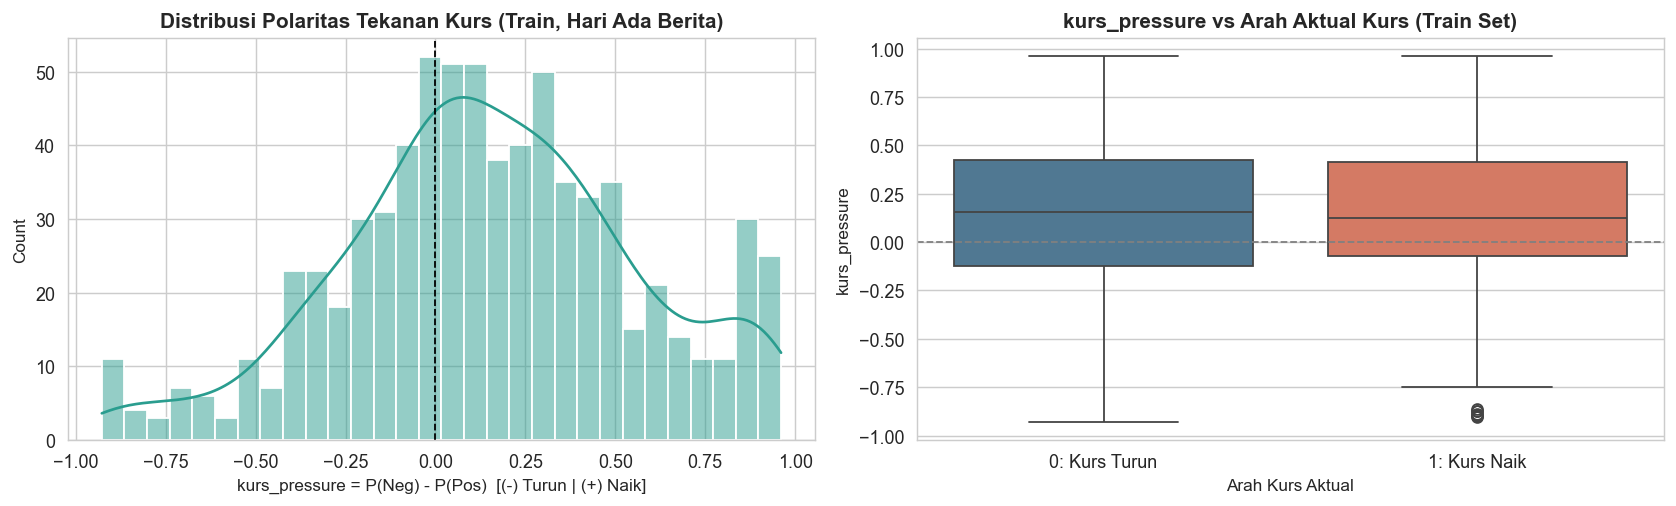

In [4]:
FINBERT_MODEL_NAME = "ProsusAI/finbert"
fin_tok, fin_mod = load_hf_tokenizer_and_model(AutoModelForSequenceClassification, FINBERT_MODEL_NAME)
fin_mod = fin_mod.to(DEVICE)
for p in fin_mod.parameters():
    p.requires_grad = False
fin_mod.eval()

# Cek urutan label FinBERT secara dinamis
id2label = {int(k): str(v).lower() for k, v in fin_mod.config.id2label.items()}
pos_idx = next(i for i, lbl in id2label.items() if "pos" in lbl)
neg_idx = next(i for i, lbl in id2label.items() if "neg" in lbl)
neu_idx = next(i for i, lbl in id2label.items() if "neu" in lbl)
print(f"Mapping label FinBERT: {id2label}")

fin_map = {}
with torch.no_grad():
    for i in range(0, len(unique_titles), bs):
        batch_txt = unique_titles[i:i + bs]
        enc = fin_tok(
            batch_txt,
            padding=True,
            truncation=True,
            max_length=48,
            return_tensors="pt",
        ).to(DEVICE)
        probs = torch.softmax(fin_mod(**enc).logits, dim=-1).cpu().numpy()
        for t_str, p_arr in zip(batch_txt, probs):
            p_pos = float(p_arr[pos_idx])
            p_neg = float(p_arr[neg_idx])
            p_neu = float(p_arr[neu_idx])
            sent_pol = p_pos - p_neg               # + = berita positif, - = berita negatif
            kurs_press = p_neg - p_pos             # + = rupiah naik, - = rupiah turun
            sent_ratio = (p_pos - p_neg) / (p_pos + p_neg + 1e-8)
            cls_name = ["Positif", "Negatif", "Netral"][int(np.argmax([p_pos, p_neg, p_neu]))]
            fin_map[t_str] = {
                "finbert_pos": p_pos,
                "finbert_neg": p_neg,
                "finbert_neu": p_neu,
                "sent_polarity": sent_pol,
                "kurs_pressure": kurs_press,
                "sent_magnitude": abs(kurs_press),
                "sent_ratio": sent_ratio,
                "sent_class": cls_name,
            }

del fin_mod, fin_tok
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Agregasi fitur sentimen per hari perdagangan
sent_cols = [
    "finbert_pos", "finbert_neg", "finbert_neu",
    "sent_polarity", "kurs_pressure", "sent_magnitude", "sent_ratio",
]
daily_sent = np.zeros((len(df), len(sent_cols)), dtype=np.float32)
for i, t_list in enumerate(daily_title_lists):
    if t_list:
        mat = np.array([[fin_map[t][c] for c in sent_cols] for t in t_list], dtype=np.float32)
        daily_sent[i] = mat.mean(axis=0)

for j, c in enumerate(sent_cols):
    df[c] = daily_sent[:, j]

# Contoh interpretasi sentimen & kecenderungan pada berita Positif, Negatif, dan Netral
sample_articles = pd.DataFrame([{"title": t, **v} for t, v in fin_map.items()])
print("\nContoh Judul Berita per Kelas Sentimen & Logika Arah Kurs Indonesia:")
ex_rows = []
for cls in ["Negatif", "Positif", "Netral"]:
    sub = sample_articles[sample_articles["sent_class"] == cls]
    if cls == "Netral":
        # Ambil berita netral dengan kecenderungan kecil (~0.05 s/d 0.20)
        sub = sub[sub["sent_magnitude"].between(0.05, 0.22)].head(2)
    else:
        sub = sub.sort_values("sent_magnitude", ascending=False).head(2)
    ex_rows.append(sub)
ex_df = pd.concat(ex_rows, ignore_index=True)
ex_df["implikasi_kurs"] = np.where(
    ex_df["kurs_pressure"] > 0.2, "Kurs Naik (kuat)",
    np.where(ex_df["kurs_pressure"] > 0, "Kurs Naik (sedikit)",
    np.where(ex_df["kurs_pressure"] < -0.2, "Kurs Turun (kuat)", "Kurs Turun (sedikit)"))
)
display(ex_df[["title", "sent_class", "finbert_pos", "finbert_neg", "finbert_neu", "kurs_pressure", "implikasi_kurs"]].round(4))

# Visualisasi distribusi kurs_pressure di Train Set
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
tr_news = df.loc[is_tr & (df["has_news"] == 1)]
sns.histplot(tr_news["kurs_pressure"], bins=30, kde=True, ax=axes[0], color="#2a9d8f")
axes[0].axvline(0, color="black", linestyle="--", lw=1)
axes[0].set_title("Distribusi Polaritas Tekanan Kurs (Train, Hari Ada Berita)")
axes[0].set_xlabel("kurs_pressure = P(Neg) - P(Pos)  [(-) Turun | (+) Naik]")

sns.boxplot(data=tr_news, x="y_dir", y="kurs_pressure", ax=axes[1], palette=["#457b9d", "#e76f51"])
axes[1].axhline(0, color="gray", linestyle="--", lw=1)
axes[1].set_xticklabels(["0: Kurs Turun", "1: Kurs Naik"])
axes[1].set_title("kurs_pressure vs Arah Aktual Kurs (Train Set)")
axes[1].set_xlabel("Arah Kurs Aktual")
plt.tight_layout()
plt.show()


## 5. Topic Modelling dengan BERTopic + Reduksi Dimensi (UMAP & PCA, Fit di Train Saja)

- **BERTopic** di-*fit* **hanya pada hari berberita di Train Set** (`is_train & has_news == 1`) menggunakan *embedding* `all-MiniLM-L6-v2` (freeze weights) + UMAP 5D + HDBSCAN + c-TF-IDF.
- Seluruh hari berberita di Train, Val, dan Test ditransformasikan dengan model hasil *fit* Train tersebut (hari tanpa berita diberi vektor topik `0.0`).
- Distribusi probabilitas topik kemudian direduksi dimensinya dengan **PCA** (fit di Train) menjadi fitur padat `topic_pca_0..4`, dan dipetakan pula dengan **UMAP 2D** (fit di Train) menjadi `topic_umap_0, topic_umap_1` + visualisasi klaster!


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1082.25it/s]

BERTopic selesai di-fit pada 729 hari Train berberita -> 10 topik ditemukan.


,Topic,Count,Name,Representation,Representative_Docs
0,-1,170,-1_china_says_biden_korea,"[china, says, biden, korea, global, minister, ...",[Singapore’s Lawrence Wong sworn in as new pri...
1,0,167,0_ukraine_russia_russian_putin,"[ukraine, russia, russian, putin, war, moscow,...",[10-year U.S. Treasury yield is little changed...
2,1,146,1_china_beijing_chinese_xi,"[china, beijing, chinese, xi, says, biden, pre...",[China hawk says Beijing could attack Taiwan b...
3,2,49,2_israel_gaza_hamas_israeli,"[israel, gaza, hamas, israeli, war, iran, red,...",[Gaza’s economy is in ruins as Israel-Hamas wa...
4,3,43,3_oil_crude_prices_dollar,"[oil, crude, prices, dollar, oil prices, crude...",[Crude oil futures sell off after surging on M...
5,4,40,4_energy_fund_uae_oil,"[energy, fund, uae, oil, arab, opec, climate, ...",[Greta Thunberg on Abu Dhabi’s oil chief leadi...
6,5,34,5_inflation_bank_central_central bank,"[inflation, bank, central, central bank, rates...",[Switzerland becomes first major economy to cu...
7,6,30,6_bank_credit_ceo_jpmorgan,"[bank, credit, ceo, jpmorgan, suisse, credit s...",[Credit Suisse shares plunge 18% as bank annou...
8,7,17,7_investors_stock_need_know,"[investors, stock, need, know, things, things ...",[5 things to know before the stock market open...
9,8,17,8_recession_2024_global_year,"[recession, 2024, global, year, imf, growth, f...","[From Dimon and Blinken, to Altman and Lagarde..."


Dimensi BERTopic probs: (1201, 10) -> direduksi ke PCA-5 (Explained Var: 59.74%) + UMAP-2D


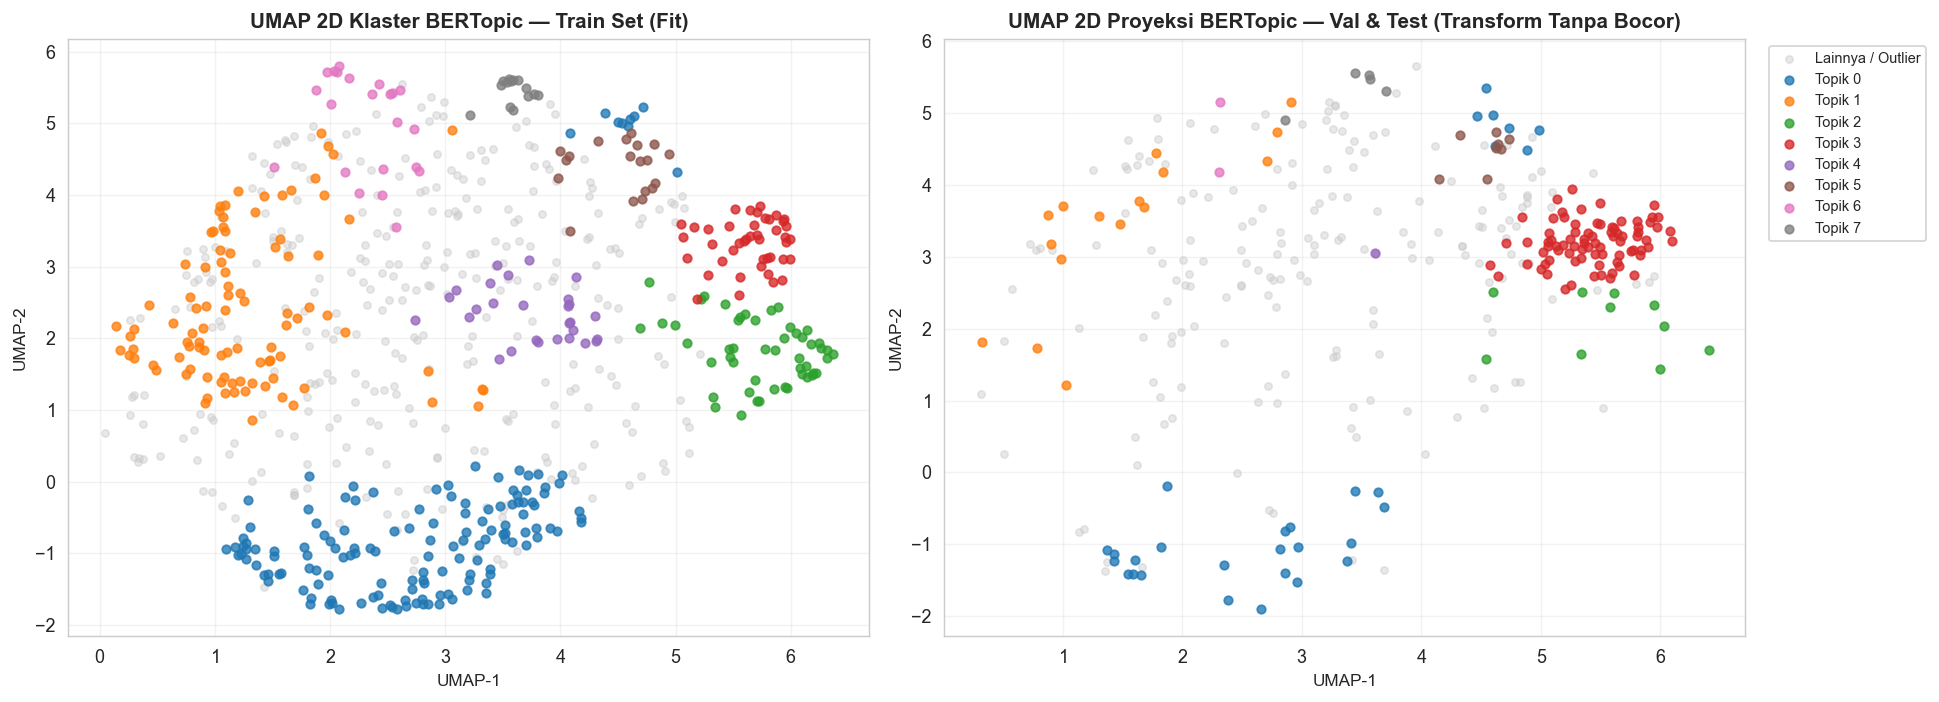

In [5]:
try:
    st_model = SentenceTransformer("all-MiniLM-L6-v2", device=DEVICE, local_files_only=True)
except Exception:
    st_model = SentenceTransformer("all-MiniLM-L6-v2", device=DEVICE)

for p in st_model.parameters():
    p.requires_grad = False
st_model.eval()

daily_topic_docs = [
    f"{t}. {b[:500]}".strip() if hn == 1 else ""
    for t, b, hn in zip(df["title_clean"], df["norm_clean"], df["has_news"])
]

news_mask = df["has_news"].values == 1
tr_news_mask = is_tr & news_mask
va_news_mask = is_va & news_mask
te_news_mask = is_te & news_mask

news_docs_all = [d for d, m in zip(daily_topic_docs, news_mask) if m]
with torch.no_grad():
    news_embs_all = st_model.encode(
        news_docs_all, batch_size=64, show_progress_bar=False, normalize_embeddings=True
    )

# Map kembali ke indeks 0..N-1
emb_minilm_full = np.zeros((len(df), news_embs_all.shape[1]), dtype=np.float32)
emb_minilm_full[news_mask] = news_embs_all

tr_docs = [daily_topic_docs[i] for i in np.where(tr_news_mask)[0]]
tr_embs = emb_minilm_full[tr_news_mask]

# Fit BERTopic HANYA pada Train set berberita
umap_bt = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED)
hdbscan_bt = HDBSCAN(min_cluster_size=15, min_samples=5, metric="euclidean", cluster_selection_method="eom", prediction_data=True)
vec_bt = CountVectorizer(stop_words="english", min_df=3, ngram_range=(1, 2))

topic_model = BERTopic(
    embedding_model=st_model,
    umap_model=umap_bt,
    hdbscan_model=hdbscan_bt,
    vectorizer_model=vec_bt,
    calculate_probabilities=True,
    verbose=False,
)

tr_topics, tr_probs = topic_model.fit_transform(tr_docs, tr_embs)
bt_info = topic_model.get_topic_info()
n_bt_topics = int((bt_info["Topic"] != -1).sum())
print(f"BERTopic selesai di-fit pada {len(tr_docs)} hari Train berberita -> {n_bt_topics} topik ditemukan.")
display(bt_info.head(12))

# Transform seluruh hari berberita (Train, Val, Test) menggunakan model Train
all_news_docs = [daily_topic_docs[i] for i in np.where(news_mask)[0]]
all_news_topics, all_news_probs = topic_model.transform(all_news_docs, emb_minilm_full[news_mask])

all_news_probs = np.asarray(all_news_probs)
if all_news_probs.ndim == 1:
    # Fallback jika probabilitas berbentuk 1D
    uniq_t = sorted([t for t in set(tr_topics) if t != -1])
    onehot = np.zeros((len(all_news_topics), max(len(uniq_t), 1)), dtype=np.float32)
    t_to_col = {t: j for j, t in enumerate(uniq_t)}
    for r_idx, t_val in enumerate(all_news_topics):
        if t_val in t_to_col:
            onehot[r_idx, t_to_col[t_val]] = 1.0
    all_news_probs = onehot

n_prob_cols = all_news_probs.shape[1]
topic_prob_full = np.zeros((len(df), n_prob_cols), dtype=np.float32)
topic_prob_full[news_mask] = all_news_probs

df["bt_topic"] = -2  # tanpa berita
df.loc[news_mask, "bt_topic"] = all_news_topics

# 1) Reduksi dimensi probabilitas topik BERTopic dengan PCA (FIT HANYA DI TRAIN)
TOPIC_PCA_DIM = min(5, n_prob_cols)
scaler_top = StandardScaler().fit(topic_prob_full[is_tr])
pca_top = PCA(n_components=TOPIC_PCA_DIM, random_state=SEED).fit(
    scaler_top.transform(topic_prob_full[is_tr])
)
topic_pca_feats = pca_top.transform(scaler_top.transform(topic_prob_full))
topic_pca_cols = [f"topic_pca_{i}" for i in range(TOPIC_PCA_DIM)]
for i, c in enumerate(topic_pca_cols):
    df[c] = topic_pca_feats[:, i]

# 2) Reduksi dimensi embedding semantik ke UMAP 2D (FIT HANYA DI TRAIN berberita, lalu transform Val & Test)
umap_2d = UMAP(n_neighbors=15, n_components=2, min_dist=0.1, metric="cosine", random_state=SEED)
umap_2d.fit(tr_embs)
umap_2d_news = umap_2d.transform(emb_minilm_full[news_mask])
df["topic_umap_0"] = 0.0
df["topic_umap_1"] = 0.0
df.loc[news_mask, "topic_umap_0"] = umap_2d_news[:, 0]
df.loc[news_mask, "topic_umap_1"] = umap_2d_news[:, 1]
topic_umap_cols = ["topic_umap_0", "topic_umap_1"]

print(f"Dimensi BERTopic probs: {topic_prob_full.shape} -> direduksi ke PCA-{TOPIC_PCA_DIM} (Explained Var: {pca_top.explained_variance_ratio_.sum()*100:.2f}%) + UMAP-2D")

# Visualisasi UMAP 2D BERTopic: Train (Fit) vs Val/Test (Transform)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sub_tr = df.loc[tr_news_mask]
sub_vt = df.loc[va_news_mask | te_news_mask]

top_ids = bt_info[bt_info["Topic"] != -1]["Topic"].head(8).tolist()
palette = sns.color_palette("tab10", len(top_ids))
cmap_t = {tid: palette[i] for i, tid in enumerate(top_ids)}

for ax, sub_df, title in [
    (axes[0], sub_tr, "UMAP 2D Klaster BERTopic — Train Set (Fit)"),
    (axes[1], sub_vt, "UMAP 2D Proyeksi BERTopic — Val & Test (Transform Tanpa Bocor)"),
]:
    m_other = ~sub_df["bt_topic"].isin(top_ids)
    ax.scatter(sub_df.loc[m_other, "topic_umap_0"], sub_df.loc[m_other, "topic_umap_1"], c="#cccccc", s=16, alpha=0.45, label="Lainnya / Outlier")
    for tid in top_ids:
        m_t = sub_df["bt_topic"] == tid
        if m_t.sum() > 0:
            ax.scatter(sub_df.loc[m_t, "topic_umap_0"], sub_df.loc[m_t, "topic_umap_1"], color=cmap_t[tid], s=22, alpha=0.78, label=f"Topik {tid}")
    ax.set_title(title)
    ax.set_xlabel("UMAP-1")
    ax.set_ylabel("UMAP-2")
    ax.grid(True, alpha=0.25)

axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

del st_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


## 6. Stage 1: Parameter Tuning Classifier Arah Return (BERT Title PCA + Sentimen Polaritas BERT + BERTopic Tereduksi)

Menggabungkan seluruh fitur teks (yang sudah bebas kebocoran) untuk memprediksi arah kurs harian `y_dir` (`1 = Kurs Naik`, `0 = Kurs Turun`):
- Melakukan **Parameter Tuning** pada **Validation Set** untuk kombinasi jumlah komponen PCA judul BERT (`n_bert_pca` $\in \{4, 8, 12\}$) dan hiperparameter model (`LogisticRegression`, `GradientBoostingClassifier`, `RandomForestClassifier`).
- Untuk menghasilkan fitur `pred_dir_prob` di **Train set** tanpa *in-sample leakage*, digunakan **5-Fold Out-of-Fold (OOF) murni di dalam Train set** memakai kombinasi parameter terbaik hasil tuning Validation.


In [6]:
sent_s1_cols = [
    "kurs_pressure", "sent_polarity", "sent_magnitude", "sent_ratio",
    "finbert_pos", "finbert_neg", "finbert_neu", "has_news",
]

y_s1_tr = df.loc[is_tr, "y_dir"].values
y_s1_va = df.loc[is_va, "y_dir"].values
y_s1_te = df.loc[is_te, "y_dir"].values

# Grid Parameter Tuning Stage 1 (Fit Train -> Evaluasi di Val, tanpa menyentuh Test!)
s1_param_grid = []
for n_pca in [4, 8, 12]:
    for c_val in [0.02, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0]:
        s1_param_grid.append((
            f"LogReg(C={c_val}, pca={n_pca})",
            n_pca,
            lambda c=c_val: LogisticRegression(C=c, class_weight="balanced", max_iter=1000, random_state=SEED),
        ))
    for n_est, md, lr_gb in [(50, 2, 0.03), (100, 2, 0.03), (80, 3, 0.04)]:
        s1_param_grid.append((
            f"GradBoost(n={n_est}, d={md}, lr={lr_gb}, pca={n_pca})",
            n_pca,
            lambda ne=n_est, d=md, l=lr_gb: GradientBoostingClassifier(
                n_estimators=ne, max_depth=d, learning_rate=l, subsample=0.8, random_state=SEED
            ),
        ))
    for n_est, md, msl in [(150, 3, 12), (200, 5, 8)]:
        s1_param_grid.append((
            f"RF(n={n_est}, d={md}, leaf={msl}, pca={n_pca})",
            n_pca,
            lambda ne=n_est, d=md, m=msl: RandomForestClassifier(
                n_estimators=ne, max_depth=d, min_samples_leaf=m, class_weight="balanced", random_state=SEED
            ),
        ))

val_results = []
for name, n_pca, factory in s1_param_grid:
    cols_k = bert_pca_cols[:n_pca] + sent_s1_cols + topic_pca_cols + topic_umap_cols
    sc_k = StandardScaler().fit(df.loc[is_tr, cols_k])
    clf_k = factory().fit(sc_k.transform(df.loc[is_tr, cols_k]), y_s1_tr)
    p_va = clf_k.predict_proba(sc_k.transform(df.loc[is_va, cols_k]))[:, 1]
    pred_va = (p_va >= 0.5).astype(int)
    val_results.append({
        "Model": name,
        "n_bert_pca": n_pca,
        "Val Acc (%)": round(accuracy_score(y_s1_va, pred_va) * 100, 2),
        "Val BalAcc (%)": round(balanced_accuracy_score(y_s1_va, pred_va) * 100, 2),
        "Val Macro F1 (%)": round(f1_score(y_s1_va, pred_va, average="macro") * 100, 2),
        "Val ROC-AUC": round(roc_auc_score(y_s1_va, p_va), 4),
    })

val_s1_df = pd.DataFrame(val_results).sort_values(["Val BalAcc (%)", "Val ROC-AUC"], ascending=False).reset_index(drop=True)
best_s1_row = val_s1_df.iloc[0]
best_s1_name = best_s1_row["Model"]
best_s1_n_pca, best_s1_factory = next((n_p, fac) for nm, n_p, fac in s1_param_grid if nm == best_s1_name)

stage1_cols = bert_pca_cols[:best_s1_n_pca] + sent_s1_cols + topic_pca_cols + topic_umap_cols
print(f"Total kombinasi tuning Stage 1: {len(s1_param_grid)} | Terbaik (Val): {best_s1_name} ({len(stage1_cols)} fitur)")
display(val_s1_df.head(10))

# Hasilkan prediksi OOF (5-Fold murni di dalam Train) agar Stage 2 tidak mengalami leakage di Train
scaler_s1 = StandardScaler().fit(df.loc[is_tr, stage1_cols])
X_s1_tr = scaler_s1.transform(df.loc[is_tr, stage1_cols])
X_s1_va = scaler_s1.transform(df.loc[is_va, stage1_cols])
X_s1_te = scaler_s1.transform(df.loc[is_te, stage1_cols])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof_tr_prob = np.zeros(len(y_s1_tr), dtype=np.float32)
for tr_f, ho_f in skf.split(X_s1_tr, y_s1_tr):
    sc_f = StandardScaler().fit(df.loc[is_tr, stage1_cols].iloc[tr_f])
    clf_f = best_s1_factory().fit(
        sc_f.transform(df.loc[is_tr, stage1_cols].iloc[tr_f]),
        y_s1_tr[tr_f],
    )
    oof_tr_prob[ho_f] = clf_f.predict_proba(sc_f.transform(df.loc[is_tr, stage1_cols].iloc[ho_f]))[:, 1]

# Fit final pada seluruh Train untuk prediksi Val & Test
final_s1_clf = best_s1_factory().fit(X_s1_tr, y_s1_tr)
p_s1_va = final_s1_clf.predict_proba(X_s1_va)[:, 1]
p_s1_te = final_s1_clf.predict_proba(X_s1_te)[:, 1]

df.loc[is_tr, "pred_dir_prob"] = oof_tr_prob
df.loc[is_va, "pred_dir_prob"] = p_s1_va
df.loc[is_te, "pred_dir_prob"] = p_s1_te
df["pred_dir_class"] = (df["pred_dir_prob"] >= 0.5).astype(int)
df["pred_dir_signed"] = 2.0 * df["pred_dir_prob"] - 1.0  # [-1, +1]

def eval_cls_row(label, y_true, probs):
    pred = (probs >= 0.5).astype(int)
    return {
        "Evaluasi": label,
        "Accuracy (%)": round(accuracy_score(y_true, pred) * 100, 2),
        "Balanced Acc (%)": round(balanced_accuracy_score(y_true, pred) * 100, 2),
        "Macro F1 (%)": round(f1_score(y_true, pred, average="macro") * 100, 2),
        "ROC-AUC": round(roc_auc_score(y_true, probs), 4),
    }

s1_summary = pd.DataFrame([
    eval_cls_row("Train (5-Fold OOF)", y_s1_tr, oof_tr_prob),
    eval_cls_row("Validation", y_s1_va, p_s1_va),
    eval_cls_row("Test", y_s1_te, p_s1_te),
    eval_cls_row("Rule Sentimen Murni (Test: kurs_pressure>0)", y_s1_te, 0.5 + 0.5 * df.loc[is_te, "kurs_pressure"].values),
])
display(s1_summary)


Total kombinasi tuning Stage 1: 36 | Terbaik (Val): LogReg(C=0.02, pca=4) (19 fitur)


,Model,n_bert_pca,Val Acc (%),Val BalAcc (%),Val Macro F1 (%),Val ROC-AUC
0,"LogReg(C=0.02, pca=4)",4,55.00,56.03,54.38,0.5495
1,"LogReg(C=0.05, pca=4)",4,54.44,55.43,53.87,0.5424
2,"LogReg(C=0.1, pca=12)",12,53.33,54.46,52.49,0.5281
3,"LogReg(C=0.2, pca=12)",12,53.33,54.39,52.63,0.5274
4,"LogReg(C=0.1, pca=4)",4,53.33,54.24,52.86,0.5372
5,"LogReg(C=0.05, pca=12)",12,52.78,54.09,51.52,0.5310
6,"LogReg(C=0.2, pca=4)",4,52.78,53.72,52.25,0.5344
7,"LogReg(C=1.0, pca=4)",4,52.78,53.72,52.25,0.5330
8,"LogReg(C=0.5, pca=4)",4,52.78,53.72,52.25,0.5326
9,"RF(n=200, d=5, leaf=8, pca=12)",12,53.33,53.50,53.33,0.5112


,Evaluasi,Accuracy (%),Balanced Acc (%),Macro F1 (%),ROC-AUC
0,Train (5-Fold OOF),53.81,54.02,53.74,0.5490
1,Validation,55.00,56.03,54.38,0.5495
2,Test,53.04,53.74,52.99,0.5603
3,Rule Sentimen Murni (Test: kurs_pressure>0),50.83,48.11,47.43,0.4796


## 7. Fitur Interaksi `Sentimen × Arah` & Penandaan Sentimen Tinggi

Dari hasil klasifikasi Stage 1, dibentuk fitur interaksi **Sentimen × Arah** dan penandaan eksplisit untuk kasus **Naik dengan Sentimen Tinggi** serta **Turun dengan Sentimen Tinggi** (ambang kuantil ke-70 `sent_magnitude` dihitung **murni pada hari berberita di Train Set**):
- `sent_x_dir = kurs_pressure * pred_dir_signed`
- `sent_mag_x_dir = sent_magnitude * pred_dir_signed`
- `flag_naik_sent_tinggi = 1` jika (`pred_dir_class == 1` dan `sent_magnitude >= HIGH_SENT_THRES`)
- `flag_turun_sent_tinggi = 1` jika (`pred_dir_class == 0` dan `sent_magnitude >= HIGH_SENT_THRES`)
- `sent_dir_tier` $\in \{-1, 0, +1\}$ (`+1` = Naik Sentimen Tinggi, `-1` = Turun Sentimen Tinggi, `0` = Lainnya)


Ambang Sentimen Tinggi (Persentil ke-70 Train): 0.6237


,Split,Kategori Sentimen x Arah,Jumlah Hari,Proporsi (%),Mean Log Return Aktual,Aktual Naik (%)
0,Train,Naik + Sentimen Tinggi,66,7.9,-0.000073,53.0
1,Train,Sentimen Rendah/Netral,621,73.9,0.000269,57.3
2,Train,Turun + Sentimen Tinggi,153,18.2,-0.000243,48.4
3,Val,Naik + Sentimen Tinggi,5,2.8,-0.001624,20.0
4,Val,Sentimen Rendah/Netral,127,70.6,0.000386,58.3
5,Val,Turun + Sentimen Tinggi,48,26.7,-0.000176,43.8
6,Test,Naik + Sentimen Tinggi,15,8.3,0.000214,53.3
7,Test,Sentimen Rendah/Netral,132,72.9,0.000403,59.8
8,Test,Turun + Sentimen Tinggi,34,18.8,0.000055,50.0


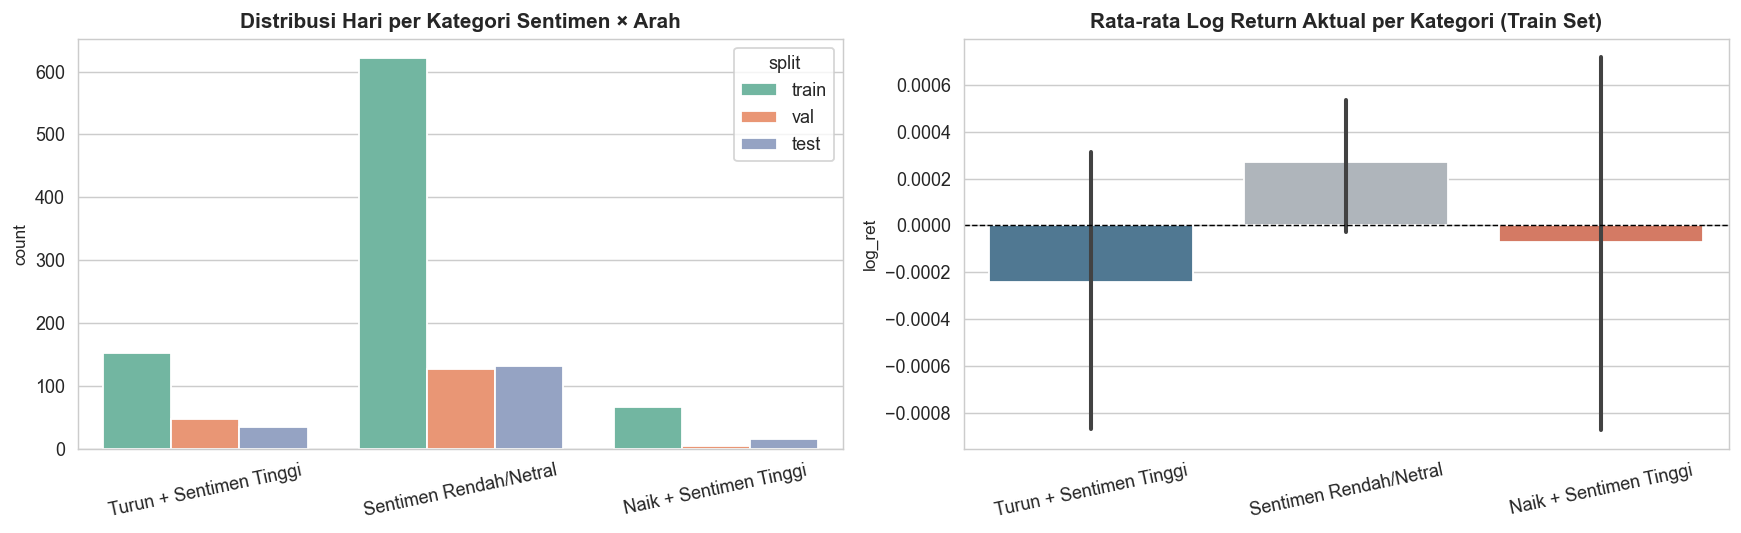

In [7]:
# Hitung threshold sentimen tinggi HANYA pada Train set (hari yang memiliki berita)
tr_sent_mags = df.loc[is_tr & (df["has_news"] == 1), "sent_magnitude"].values
HIGH_SENT_THRES = float(np.quantile(tr_sent_mags, 0.70))
print(f"Ambang Sentimen Tinggi (Persentil ke-70 Train): {HIGH_SENT_THRES:.4f}")

df["sent_x_dir"] = df["kurs_pressure"] * df["pred_dir_signed"]
df["sent_mag_x_dir"] = df["sent_magnitude"] * df["pred_dir_signed"]

df["flag_naik_sent_tinggi"] = ((df["pred_dir_class"] == 1) & (df["sent_magnitude"] >= HIGH_SENT_THRES)).astype(int)
df["flag_turun_sent_tinggi"] = ((df["pred_dir_class"] == 0) & (df["sent_magnitude"] >= HIGH_SENT_THRES)).astype(int)
df["sent_dir_tier"] = df["flag_naik_sent_tinggi"] - df["flag_turun_sent_tinggi"]

tier_names = {1: "Naik + Sentimen Tinggi", 0: "Sentimen Rendah/Netral", -1: "Turun + Sentimen Tinggi"}
df["sent_dir_tier_label"] = df["sent_dir_tier"].map(tier_names)

# Ringkasan per split
tier_summary = []
for sp_name, m in [("Train", is_tr), ("Val", is_va), ("Test", is_te)]:
    sub = df.loc[m]
    for tier_val, tier_lbl in tier_names.items():
        g = sub[sub["sent_dir_tier"] == tier_val]
        tier_summary.append({
            "Split": sp_name,
            "Kategori Sentimen x Arah": tier_lbl,
            "Jumlah Hari": len(g),
            "Proporsi (%)": round(len(g) / len(sub) * 100, 1),
            "Mean Log Return Aktual": round(float(g["log_ret"].mean()), 6) if len(g) > 0 else np.nan,
            "Aktual Naik (%)": round(float(g["y_dir"].mean() * 100), 1) if len(g) > 0 else np.nan,
        })
display(pd.DataFrame(tier_summary))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2))
order_lbl = ["Turun + Sentimen Tinggi", "Sentimen Rendah/Netral", "Naik + Sentimen Tinggi"]
sns.countplot(data=df, x="sent_dir_tier_label", hue="split", order=order_lbl, ax=axes[0], palette="Set2")
axes[0].set_title("Distribusi Hari per Kategori Sentimen × Arah")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=12)

sns.barplot(data=df.loc[is_tr], x="sent_dir_tier_label", y="log_ret", order=order_lbl, ax=axes[1], palette=["#457b9d", "#adb5bd", "#e76f51"])
axes[1].axhline(0, color="black", lw=0.8, linestyle="--")
axes[1].set_title("Rata-rata Log Return Aktual per Kategori (Train Set)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=12)
plt.tight_layout()
plt.show()


## 8. Penggabungan dengan Fitur Time Series (Strictly Causal $\le t-1$) & Persiapan Sequence Bi-LSTM

Seluruh fitur *time series* dihitung menggunakan nilai lag $\le t-1$ (tanpa melihat `rate_mid` hari $t$):
- `ret_lag1`, `ret_lag2`, `ret_lag3`, `ret_lag5`
- `vol_5d`, `vol_10d`
- `dist_ma5`, `dist_ma10`, `dist_ma20`
- `rsi_14`, `consec_up_days`, `spread_lag1`
- `dow_sin`, `dow_cos`

Lalu dibuat jendela sekuensial (`SEQ_LEN = 10` hari) dan dilakukan standarisasi fitur & target **murni pada Train Set**.


In [8]:
# 1. Fitur Time Series strictly causal (<= t-1)
df["ret_lag1"] = df["log_ret"].shift(1)
df["ret_lag2"] = df["log_ret"].shift(2)
df["ret_lag3"] = df["log_ret"].shift(3)
df["ret_lag5"] = df["log_ret"].shift(5)

df["vol_5d"] = df["log_ret"].shift(1).rolling(5).std()
df["vol_10d"] = df["log_ret"].shift(1).rolling(10).std()

for w in [5, 10, 20]:
    ma_w = df["rate_mid"].shift(1).rolling(w).mean()
    df[f"dist_ma{w}"] = df["rate_mid"].shift(1) / ma_w - 1.0

# RSI 14 hari (strictly t-1)
delta = df["rate_mid"].diff().shift(1)
gain = delta.clip(lower=0).rolling(14).mean()
loss = (-delta.clip(upper=0)).rolling(14).mean()
rs = gain / (loss + 1e-9)
df["rsi_14"] = (100.0 - (100.0 / (1.0 + rs))) / 100.0

# Streak hari naik/turun berturut-turut hingga t-1
consecs, cur = [], 0
for r in df["log_ret"]:
    if r > 0:
        cur = cur + 1 if cur > 0 else 1
    elif r < 0:
        cur = cur - 1 if cur < 0 else -1
    else:
        cur = 0
    consecs.append(cur)
df["consec_up_days"] = pd.Series(consecs, index=df.index).shift(1)

df["spread_lag1"] = ((df["Kurs Jual"] - df["Kurs Beli"]) / df["rate_mid"]).shift(1)
dow = df[date_col].dt.dayofweek
df["dow_sin"] = np.sin(2 * np.pi * dow / 5.0)
df["dow_cos"] = np.cos(2 * np.pi * dow / 5.0)

ts_cols = [
    "ret_lag1", "ret_lag2", "ret_lag3", "ret_lag5",
    "vol_5d", "vol_10d", "dist_ma5", "dist_ma10", "dist_ma20",
    "rsi_14", "consec_up_days", "spread_lag1", "dow_sin", "dow_cos",
]

nlp_stage2_cols = [
    "kurs_pressure", "sent_magnitude", "has_news",
    "pred_dir_prob", "pred_dir_signed",
    "sent_x_dir", "sent_mag_x_dir",
    "flag_naik_sent_tinggi", "flag_turun_sent_tinggi", "sent_dir_tier",
] + topic_pca_cols + bert_pca_cols[:4]

multimodal_cols = ts_cols + nlp_stage2_cols

# Hapus baris awal warm-up rolling (20 hari pertama)
df_model = df.dropna(subset=multimodal_cols + ["log_ret"]).reset_index(drop=True)

# Pertahankan tanggal batas split awal agar tidak berubah
m_tr = (df_model[date_col] <= train_end_date).values
m_va = ((df_model[date_col] > train_end_date) & (df_model[date_col] <= val_end_date)).values
m_te = (df_model[date_col] > val_end_date).values

print(f"Baris valid setelah warm-up TS: {len(df_model):,} | Train={m_tr.sum()}, Val={m_va.sum()}, Test={m_te.sum()}")
print(f"Fitur TS Only    : {len(ts_cols)} fitur")
print(f"Fitur Multimodal : {len(multimodal_cols)} fitur ({len(ts_cols)} TS + {len(nlp_stage2_cols)} NLP/Sent×Arah/Topik)")

# Bangun Sequence Sliding Window untuk Bi-LSTM (fit scaler HANYA di Train!)
SEQ_LEN = 10

def build_sequences(frame: pd.DataFrame, feature_cols: list[str], seq_len: int = SEQ_LEN):
    sc_x = StandardScaler().fit(frame.loc[m_tr, feature_cols])
    X_scaled = sc_x.transform(frame[feature_cols]).astype(np.float32)

    y_raw = frame["log_ret"].values.astype(np.float32)
    mu_y = float(y_raw[m_tr].mean())
    std_y = float(y_raw[m_tr].std() + 1e-9)
    y_scaled = ((y_raw - mu_y) / std_y).astype(np.float32)

    X_seqs, y_seqs_s, y_seqs_raw, y_dirs, seq_splits, seq_dates, prev_rates, curr_rates = [], [], [], [], [], [], [], []
    split_arr = np.where(m_tr, "train", np.where(m_va, "val", "test"))
    dates_arr = frame[date_col].values
    rates_arr = frame["rate_mid"].values

    for t in range(seq_len - 1, len(frame)):
        X_seqs.append(X_scaled[t - seq_len + 1 : t + 1])
        y_seqs_s.append(y_scaled[t])
        y_seqs_raw.append(y_raw[t])
        y_dirs.append(int(y_raw[t] > 0))
        seq_splits.append(split_arr[t])
        seq_dates.append(dates_arr[t])
        prev_rates.append(rates_arr[t - 1])
        curr_rates.append(rates_arr[t])

    return {
        "X": np.array(X_seqs, dtype=np.float32),
        "y_s": np.array(y_seqs_s, dtype=np.float32),
        "y_raw": np.array(y_seqs_raw, dtype=np.float32),
        "y_dir": np.array(y_dirs, dtype=np.int64),
        "split": np.array(seq_splits),
        "dates": pd.to_datetime(seq_dates),
        "prev_rate": np.array(prev_rates, dtype=np.float64),
        "curr_rate": np.array(curr_rates, dtype=np.float64),
        "mu_y": mu_y,
        "std_y": std_y,
        "scaler_x": sc_x,
    }

seq_ts = build_sequences(df_model, ts_cols, SEQ_LEN)
seq_mm = build_sequences(df_model, multimodal_cols, SEQ_LEN)
print("Shape tensor sequence Multimodal:", seq_mm["X"].shape,
      "| Train:", (seq_mm["split"] == "train").sum(),
      "| Val:", (seq_mm["split"] == "val").sum(),
      "| Test:", (seq_mm["split"] == "test").sum())


Baris valid setelah warm-up TS: 1,181 | Train=820, Val=180, Test=181
Fitur TS Only    : 14 fitur
Fitur Multimodal : 33 fitur (14 TS + 19 NLP/Sent×Arah/Topik)
Shape tensor sequence Multimodal: (1172, 10, 33) | Train: 811 | Val: 180 | Test: 181


## 9. Parameter Tuning & Perbandingan Model: ML Regression, MLP, LSTM, dan Bi-LSTM

Untuk perbandingan yang adil dan bebas *data leakage*, seluruh model dilatih pada **Train Set** dan seluruh hiperparameternya dituning pada **Validation Set** (tanpa menyentuh Test Set):
1. **Machine Learning Regression-Based**: `Ridge`, `ElasticNet`, `GradientBoostingRegressor`, dan `RandomForestRegressor`.
2. **Neural Tabular (`MLP`)**: *Multi-Layer Perceptron* PyTorch dengan *LayerNorm*, *Dropout*, dan *Early Stopping*.
3. **Neural Sequential (`LSTM` vs `Bi-LSTM`)**:
   - **LSTM** (*unidirectional*, `bidirectional=False`)
   - **Bi-LSTM** (*bidirectional*, `bidirectional=True`) — untuk versi **Time-Series Only** maupun **Multimodal Lengkap**.
4. **Expert Cabang Modalitas (Persiapan Late Fusion)**: melatih pula *expert* khusus **NLP-Only** dan **TS-Only** agar dapat digabungkan pada tahap **Late Fusion**.


In [9]:
class TabularMLPRegressor(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int = 32, dropout: float = 0.35):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(input_dim),
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 16),
            nn.Tanh(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(16, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


class SeqLSTMRegressor(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int = 32, num_layers: int = 1,
                 dropout: float = 0.35, bidirectional: bool = True):
        super().__init__()
        self.in_norm = nn.LayerNorm(input_dim)
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        out_dim = hidden_dim * (2 if bidirectional else 1)
        self.head = nn.Sequential(
            nn.LayerNorm(out_dim),
            nn.Dropout(dropout),
            nn.Linear(out_dim, 16),
            nn.Tanh(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(16, 1),
        )

    def forward(self, x):
        x = self.in_norm(x)
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)


def train_pytorch_regressor(model: nn.Module, X_tr_np, y_tr_s_np, X_va_np, y_va_s_np, X_te_np,
                            mu_y: float, std_y: float, lr: float = 1e-3, weight_decay: float = 1e-3,
                            dir_lambda: float = 0.15, batch_size: int = 32, epochs: int = 70, patience: int = 12):
    set_seed(SEED)
    X_tr = torch.tensor(X_tr_np, dtype=torch.float32)
    y_tr = torch.tensor(y_tr_s_np, dtype=torch.float32)
    X_va = torch.tensor(X_va_np, dtype=torch.float32).to(DEVICE)
    y_va = torch.tensor(y_va_s_np, dtype=torch.float32).to(DEVICE)
    X_te = torch.tensor(X_te_np, dtype=torch.float32).to(DEVICE)

    loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)
    model = model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    def composite_loss(pred_s, target_s):
        mse = nn.functional.mse_loss(pred_s, target_s)
        zero_s = -mu_y / std_y
        sign_hinge = torch.relu(-(pred_s - zero_s) * torch.sign(target_s - zero_s)).mean()
        return mse + dir_lambda * sign_hinge

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    wait = 0
    tr_hist, va_hist = [], []

    for _ in range(epochs):
        model.train()
        ep_losses = []
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = composite_loss(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            ep_losses.append(float(loss.item()))

        model.eval()
        with torch.no_grad():
            va_loss = float(composite_loss(model(X_va), y_va).item())

        tr_hist.append(float(np.mean(ep_losses)))
        va_hist.append(va_loss)

        if va_loss < best_val_loss - 1e-6:
            best_val_loss = va_loss
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        pred_va_raw = model(X_va).cpu().numpy() * std_y + mu_y
        pred_te_raw = model(X_te).cpu().numpy() * std_y + mu_y

    return {
        "model": model,
        "pred_va": pred_va_raw,
        "pred_te": pred_te_raw,
        "tr_hist": tr_hist,
        "va_hist": va_hist,
        "best_epoch": len(tr_hist) - wait,
    }


def eval_regression_metrics(name: str, y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    r2 = float(r2_score(y_true, y_pred))
    dir_true = (y_true > 0).astype(int)
    dir_pred = (y_pred > 0).astype(int)
    return {
        "Model": name,
        "RMSE": round(rmse, 6),
        "MAE": round(mae, 6),
        "R2": round(r2, 4),
        "DirAcc (%)": round(float(accuracy_score(dir_true, dir_pred) * 100), 2),
        "BalAcc (%)": round(float(balanced_accuracy_score(dir_true, dir_pred) * 100), 2),
    }

# --- 1. Data Tabular Selaras dengan Val (180 baris) & Test (181 baris) ---
seq_cache_mm = {sl: build_sequences(df_model, multimodal_cols, sl) for sl in [5, 10, 15]}
seq_cache_ts = {sl: build_sequences(df_model, ts_cols, sl) for sl in [5, 10, 15]}
seq_cache_nlp = {sl: build_sequences(df_model, nlp_stage2_cols, sl) for sl in [5, 10]}

base_b = seq_cache_mm[10]
sp_base = base_b["split"]
X_tab_tr, X_tab_va, X_tab_te = base_b["X"][sp_base == "train"][:, -1, :], base_b["X"][sp_base == "val"][:, -1, :], base_b["X"][sp_base == "test"][:, -1, :]
y_tab_tr, y_tab_tr_s = base_b["y_raw"][sp_base == "train"], base_b["y_s"][sp_base == "train"]
y_va_true, y_va_s = base_b["y_raw"][sp_base == "val"], base_b["y_s"][sp_base == "val"]
y_te_true = base_b["y_raw"][sp_base == "test"]
mu_y_base, std_y_base = base_b["mu_y"], base_b["std_y"]

# Pastikan tanggal Val & Test identik di semua seq_len
assert np.array_equal(seq_cache_mm[5]["dates"][seq_cache_mm[5]["split"] == "test"], base_b["dates"][sp_base == "test"])

# --- 2. Parameter Tuning Machine Learning Regression-Based (Fit Train -> Pilih di Val) ---
def tune_sklearn_regressor(candidates_list, X_tr, y_tr, X_va, y_va, X_te):
    rows, models, preds_va, preds_te = [], [], [], []
    for label, factory in candidates_list:
        m = factory().fit(X_tr, y_tr)
        p_va = m.predict(X_va)
        p_te = m.predict(X_te)
        met = eval_regression_metrics(label, y_va, p_va)
        rows.append(met)
        models.append(m)
        preds_va.append(p_va)
        preds_te.append(p_te)
    df_t = pd.DataFrame(rows)
    min_r = df_t["RMSE"].min()
    df_t["Val Score"] = (df_t["BalAcc (%)"] - 2500.0 * (df_t["RMSE"] - min_r)).round(3)
    df_t = df_t.sort_values("Val Score", ascending=False).reset_index(drop=True)
    best_name = df_t.iloc[0]["Model"]
    b_idx = [r["Model"] for r in rows].index(best_name)
    return df_t, best_name, preds_va[b_idx], preds_te[b_idx]

ridge_cands = [(f"Ridge(alpha={a})", lambda av=a: Ridge(alpha=av, random_state=SEED)) for a in [1.0, 5.0, 10.0, 25.0, 50.0, 100.0, 200.0, 500.0]]
enet_cands = [
    (f"ElasticNet(a={a}, l1={l1})", lambda av=a, lv=l1: ElasticNet(alpha=av, l1_ratio=lv, max_iter=3000, random_state=SEED))
    for a in [0.0002, 0.0005, 0.001, 0.002] for l1 in [0.2, 0.5, 0.8]
]
gbr_cands = [
    (f"GBR(n={ne}, d={md}, lr={lr})", lambda n=ne, d=md, l=lr: GradientBoostingRegressor(n_estimators=n, max_depth=d, learning_rate=l, subsample=0.8, random_state=SEED))
    for ne in [40, 80, 120] for md in [2, 3] for lr in [0.02, 0.04]
]
rf_cands = [
    (f"RF(n={ne}, d={md}, leaf={lf})", lambda n=ne, d=md, l=lf: RandomForestRegressor(n_estimators=n, max_depth=d, min_samples_leaf=l, random_state=SEED, n_jobs=1))
    for ne in [100, 200] for md in [3, 5, 7] for lf in [10, 20]
]

ridge_tune_df, best_ridge_name, p_ridge_va, p_ridge_te = tune_sklearn_regressor(ridge_cands, X_tab_tr, y_tab_tr, X_tab_va, y_va_true, X_tab_te)
enet_tune_df, best_enet_name, p_enet_va, p_enet_te = tune_sklearn_regressor(enet_cands, X_tab_tr, y_tab_tr, X_tab_va, y_va_true, X_tab_te)
gbr_tune_df, best_gbr_name, p_gbr_va, p_gbr_te = tune_sklearn_regressor(gbr_cands, X_tab_tr, y_tab_tr, X_tab_va, y_va_true, X_tab_te)
rf_tune_df, best_rf_name, p_rf_va, p_rf_te = tune_sklearn_regressor(rf_cands, X_tab_tr, y_tab_tr, X_tab_va, y_va_true, X_tab_te)

print("ML Regression Terbaik (berdasarkan Validation Set):")
print(f"  - Ridge      : {best_ridge_name}")
print(f"  - ElasticNet : {best_enet_name}")
print(f"  - GBR        : {best_gbr_name}")
print(f"  - RF         : {best_rf_name}")

# --- 3. Parameter Tuning MLP Regressor (PyTorch) ---
mlp_configs = [
    {"hidden_dim": 16, "dropout": 0.25, "lr": 1e-3, "dir_lambda": 0.10, "weight_decay": 1e-3},
    {"hidden_dim": 32, "dropout": 0.35, "lr": 1e-3, "dir_lambda": 0.15, "weight_decay": 1e-3},
    {"hidden_dim": 32, "dropout": 0.45, "lr": 5e-4, "dir_lambda": 0.25, "weight_decay": 2e-3},
    {"hidden_dim": 64, "dropout": 0.40, "lr": 5e-4, "dir_lambda": 0.15, "weight_decay": 2e-3},
    {"hidden_dim": 64, "dropout": 0.50, "lr": 5e-4, "dir_lambda": 0.30, "weight_decay": 3e-3},
    {"hidden_dim": 32, "dropout": 0.30, "lr": 1e-3, "dir_lambda": 0.00, "weight_decay": 2e-3},
]

mlp_rows, mlp_runs = [], []
for cid, cfg in enumerate(mlp_configs):
    res = train_pytorch_regressor(
        TabularMLPRegressor(X_tab_tr.shape[1], hidden_dim=cfg["hidden_dim"], dropout=cfg["dropout"]),
        X_tab_tr, y_tab_tr_s, X_tab_va, y_va_s, X_tab_te,
        mu_y=mu_y_base, std_y=std_y_base,
        lr=cfg["lr"], weight_decay=cfg["weight_decay"], dir_lambda=cfg["dir_lambda"],
    )
    met = eval_regression_metrics(f"MLP #{cid}", y_va_true, res["pred_va"])
    mlp_rows.append({"cfg_id": cid, **cfg, "Val RMSE": met["RMSE"], "Val BalAcc (%)": met["BalAcc (%)"], "best_epoch": res["best_epoch"]})
    mlp_runs.append(res)

mlp_tune_df = pd.DataFrame(mlp_rows)
mlp_tune_df["Val Score"] = (mlp_tune_df["Val BalAcc (%)"] - 2500.0 * (mlp_tune_df["Val RMSE"] - mlp_tune_df["Val RMSE"].min())).round(3)
mlp_tune_df = mlp_tune_df.sort_values("Val Score", ascending=False).reset_index(drop=True)
best_mlp_id = int(mlp_tune_df.iloc[0]["cfg_id"])
res_mlp_mm = mlp_runs[best_mlp_id]
best_cfg_mlp = mlp_configs[best_mlp_id]
print(f"  - MLP MM     : cfg #{best_mlp_id} {best_cfg_mlp} (epoch={res_mlp_mm['best_epoch']})")

# --- 4. Parameter Tuning LSTM (Unidirectional) & Bi-LSTM (Bidirectional) ---
seq_configs = [
    {"seq_len": 5,  "hidden_dim": 16, "num_layers": 1, "dropout": 0.25, "lr": 1e-3, "dir_lambda": 0.15, "weight_decay": 1e-3},
    {"seq_len": 5,  "hidden_dim": 32, "num_layers": 1, "dropout": 0.35, "lr": 1e-3, "dir_lambda": 0.25, "weight_decay": 1e-3},
    {"seq_len": 10, "hidden_dim": 16, "num_layers": 1, "dropout": 0.25, "lr": 1e-3, "dir_lambda": 0.00, "weight_decay": 1e-3},
    {"seq_len": 10, "hidden_dim": 16, "num_layers": 1, "dropout": 0.35, "lr": 5e-4, "dir_lambda": 0.15, "weight_decay": 2e-3},
    {"seq_len": 10, "hidden_dim": 32, "num_layers": 1, "dropout": 0.25, "lr": 1e-3, "dir_lambda": 0.15, "weight_decay": 1e-3},
    {"seq_len": 10, "hidden_dim": 32, "num_layers": 1, "dropout": 0.40, "lr": 5e-4, "dir_lambda": 0.30, "weight_decay": 2e-3},
    {"seq_len": 10, "hidden_dim": 64, "num_layers": 1, "dropout": 0.40, "lr": 5e-4, "dir_lambda": 0.15, "weight_decay": 2e-3},
    {"seq_len": 10, "hidden_dim": 32, "num_layers": 2, "dropout": 0.35, "lr": 5e-4, "dir_lambda": 0.15, "weight_decay": 1e-3},
    {"seq_len": 15, "hidden_dim": 16, "num_layers": 1, "dropout": 0.35, "lr": 1e-3, "dir_lambda": 0.15, "weight_decay": 2e-3},
    {"seq_len": 15, "hidden_dim": 32, "num_layers": 1, "dropout": 0.35, "lr": 5e-4, "dir_lambda": 0.25, "weight_decay": 2e-3},
    {"seq_len": 15, "hidden_dim": 32, "num_layers": 2, "dropout": 0.40, "lr": 5e-4, "dir_lambda": 0.15, "weight_decay": 2e-3},
    {"seq_len": 15, "hidden_dim": 64, "num_layers": 1, "dropout": 0.40, "lr": 5e-4, "dir_lambda": 0.30, "weight_decay": 3e-3},
]

def run_seq_tuning(seq_cache: dict, bidirectional: bool, label_prefix: str):
    rows, runs = [], []
    for cid, cfg in enumerate(seq_configs):
        b = seq_cache[cfg["seq_len"]]
        sp = b["split"]
        tr_i, va_i, te_i = sp == "train", sp == "val", sp == "test"
        mod = SeqLSTMRegressor(
            b["X"].shape[2],
            hidden_dim=cfg["hidden_dim"],
            num_layers=cfg["num_layers"],
            dropout=cfg["dropout"],
            bidirectional=bidirectional,
        )
        res = train_pytorch_regressor(
            mod,
            b["X"][tr_i], b["y_s"][tr_i],
            b["X"][va_i], b["y_s"][va_i],
            b["X"][te_i],
            mu_y=b["mu_y"], std_y=b["std_y"],
            lr=cfg["lr"], weight_decay=cfg["weight_decay"], dir_lambda=cfg["dir_lambda"],
        )
        m_va = eval_regression_metrics(f"{label_prefix} #{cid}", b["y_raw"][va_i], res["pred_va"])
        rows.append({
            "cfg_id": cid, **cfg,
            "Val RMSE": m_va["RMSE"], "Val MAE": m_va["MAE"],
            "Val DirAcc (%)": m_va["DirAcc (%)"], "Val BalAcc (%)": m_va["BalAcc (%)"],
            "best_epoch": res["best_epoch"],
        })
        runs.append(res)

    tune_df = pd.DataFrame(rows)
    tune_df["Val Score"] = (tune_df["Val BalAcc (%)"] - 2500.0 * (tune_df["Val RMSE"] - tune_df["Val RMSE"].min())).round(3)
    tune_df = tune_df.sort_values("Val Score", ascending=False).reset_index(drop=True)
    best_cid = int(tune_df.iloc[0]["cfg_id"])
    return tune_df, runs[best_cid], seq_configs[best_cid], seq_cache[seq_configs[best_cid]["seq_len"]]

tune_lstm_df, res_lstm_mm, best_cfg_lstm, best_seq_lstm = run_seq_tuning(seq_cache_mm, bidirectional=False, label_prefix="LSTM-MM")
tune_mm_df, res_bilstm_mm, best_cfg_mm, best_seq_mm = run_seq_tuning(seq_cache_mm, bidirectional=True, label_prefix="BiLSTM-MM")
tune_ts_df, res_bilstm_ts, best_cfg_ts, best_seq_ts = run_seq_tuning(seq_cache_ts, bidirectional=True, label_prefix="BiLSTM-TS")

print(f"  - LSTM MM    : {best_cfg_lstm} (epoch={res_lstm_mm['best_epoch']})")
print(f"  - Bi-LSTM MM : {best_cfg_mm} (epoch={res_bilstm_mm['best_epoch']})")
print(f"  - Bi-LSTM TS : {best_cfg_ts} (epoch={res_bilstm_ts['best_epoch']})")

# --- 5. Expert Khusus Cabang NLP-Only & TS-Only (untuk Late Fusion) ---
b_nlp = seq_cache_nlp[10]
sp_n = b_nlp["split"]
X_nlp_tr, X_nlp_va, X_nlp_te = b_nlp["X"][sp_n == "train"][:, -1, :], b_nlp["X"][sp_n == "val"][:, -1, :], b_nlp["X"][sp_n == "test"][:, -1, :]
_, best_ridge_nlp_name, p_nlp_ridge_va, p_nlp_ridge_te = tune_sklearn_regressor(
    ridge_cands, X_nlp_tr, b_nlp["y_raw"][sp_n == "train"], X_nlp_va, y_va_true, X_nlp_te
)
res_nlp_mlp = train_pytorch_regressor(
    TabularMLPRegressor(X_nlp_tr.shape[1], hidden_dim=16, dropout=0.35),
    X_nlp_tr, b_nlp["y_s"][sp_n == "train"], X_nlp_va, b_nlp["y_s"][sp_n == "val"], X_nlp_te,
    mu_y=b_nlp["mu_y"], std_y=b_nlp["std_y"], lr=5e-4, weight_decay=2e-3, dir_lambda=0.15,
)

b_ts10 = seq_cache_ts[10]
sp_t10 = b_ts10["split"]
_, best_ridge_ts_name, p_ts_ridge_va, p_ts_ridge_te = tune_sklearn_regressor(
    ridge_cands, b_ts10["X"][sp_t10 == "train"][:, -1, :], b_ts10["y_raw"][sp_t10 == "train"],
    b_ts10["X"][sp_t10 == "val"][:, -1, :], y_va_true, b_ts10["X"][sp_t10 == "test"][:, -1, :]
)

print(f"  - Expert NLP : {best_ridge_nlp_name} & MLP-NLP (epoch={res_nlp_mlp['best_epoch']})")
print(f"  - Expert TS  : {best_ridge_ts_name} & Bi-LSTM TS")


ML Regression Terbaik (berdasarkan Validation Set):
  - Ridge      : Ridge(alpha=5.0)
  - ElasticNet : ElasticNet(a=0.0002, l1=0.2)
  - GBR        : GBR(n=120, d=2, lr=0.04)
  - RF         : RF(n=100, d=7, leaf=10)


  - MLP MM     : cfg #5 {'hidden_dim': 32, 'dropout': 0.3, 'lr': 0.001, 'dir_lambda': 0.0, 'weight_decay': 0.002} (epoch=68)


  - LSTM MM    : {'seq_len': 10, 'hidden_dim': 64, 'num_layers': 1, 'dropout': 0.4, 'lr': 0.0005, 'dir_lambda': 0.15, 'weight_decay': 0.002} (epoch=25)
  - Bi-LSTM MM : {'seq_len': 15, 'hidden_dim': 64, 'num_layers': 1, 'dropout': 0.4, 'lr': 0.0005, 'dir_lambda': 0.3, 'weight_decay': 0.003} (epoch=15)
  - Bi-LSTM TS : {'seq_len': 5, 'hidden_dim': 32, 'num_layers': 1, 'dropout': 0.35, 'lr': 0.001, 'dir_lambda': 0.25, 'weight_decay': 0.001} (epoch=2)


  - Expert NLP : Ridge(alpha=200.0) & MLP-NLP (epoch=26)
  - Expert TS  : Ridge(alpha=200.0) & Bi-LSTM TS


## 10. Skema Late Fusion & Tabel Perbandingan Lengkap (Test Set)

Pada arsitektur **Late Fusion**, prediksi dari beberapa cabang/keluarga model yang berbeda digabungkan di level output (*decision-level fusion*), dengan seluruh bobot fusion **dioptimalkan hanya pada Validation Set** (*zero leakage*):
1. **Late Fusion 1 — Dual-Modality Blend (TS Expert + NLP Expert)**:
   Menggabungkan cabang murni *Time-Series* (`Tuned Bi-LSTM TS-Only` / `Ridge TS-Only`) dan cabang murni *NLP* (`Ridge NLP-Only` / `MLP NLP-Only`) dengan bobot optimal $w \in [0, 1]$ pada Validation Set:
   $$\hat{y}_{\text{LF-Dual}} = w \cdot \hat{y}_{\text{TS}} + (1 - w) \cdot \hat{y}_{\text{NLP}}$$
2. **Late Fusion 2 — Multi-Family Weighted Blend (ML Regression + MLP + LSTM + Bi-LSTM)**:
   Menggabungkan perwakilan terbaik tiap keluarga arsitektur (`Tuned Ridge MM`, `Tuned GBR MM`, `Tuned MLP MM`, `Tuned LSTM MM`, `Tuned Bi-LSTM MM`) dengan bobot optimal yang dicari lewat *Dirichlet/Simplex Search* pada Validation Set.
3. **Late Fusion 3 — Meta-Ridge Stacking (Out-of-Sample Validation Meta-Learner)**:
   Melatih meta-regressor `Ridge` dengan regularisasi L2 di atas prediksi Validation seluruh model (`K-Fold CV` di dalam Validation untuk memilih `alpha` meta-learner), lalu diuji sekali pada Test Set.


In [10]:
# Kumpulkan prediksi Validation & Test seluruh model tunggal pada 180 hari Val & 181 hari Test yang identik
val_preds_dict = {
    "Ridge (MM)": p_ridge_va,
    "ElasticNet (MM)": p_enet_va,
    "GBR (MM)": p_gbr_va,
    "RF (MM)": p_rf_va,
    "MLP (MM)": res_mlp_mm["pred_va"],
    "LSTM (MM)": res_lstm_mm["pred_va"],
    "Bi-LSTM (MM)": res_bilstm_mm["pred_va"],
    "Bi-LSTM (TS-Only)": res_bilstm_ts["pred_va"],
    "Ridge (TS-Only)": p_ts_ridge_va,
    "Ridge (NLP-Only)": p_nlp_ridge_va,
    "MLP (NLP-Only)": res_nlp_mlp["pred_va"],
}

test_preds_dict = {
    "Ridge (MM)": p_ridge_te,
    "ElasticNet (MM)": p_enet_te,
    "GBR (MM)": p_gbr_te,
    "RF (MM)": p_rf_te,
    "MLP (MM)": res_mlp_mm["pred_te"],
    "LSTM (MM)": res_lstm_mm["pred_te"],
    "Bi-LSTM (MM)": res_bilstm_mm["pred_te"],
    "Bi-LSTM (TS-Only)": res_bilstm_ts["pred_te"],
    "Ridge (TS-Only)": p_ts_ridge_te,
    "Ridge (NLP-Only)": p_nlp_ridge_te,
    "MLP (NLP-Only)": res_nlp_mlp["pred_te"],
}

# --- Skema 1: Late Fusion Dual-Modality (TS Expert + NLP Expert) ---
# Pilih TS Expert terbaik & NLP Expert terbaik di Val
ts_expert_name = min(["Bi-LSTM (TS-Only)", "Ridge (TS-Only)"], key=lambda k: eval_regression_metrics(k, y_va_true, val_preds_dict[k])["RMSE"])
nlp_expert_name = min(["Ridge (NLP-Only)", "MLP (NLP-Only)"], key=lambda k: eval_regression_metrics(k, y_va_true, val_preds_dict[k])["RMSE"])

best_w_dual, best_score_dual = 0.5, -1e9
min_rmse_dual = min(
    eval_regression_metrics("ts", y_va_true, val_preds_dict[ts_expert_name])["RMSE"],
    eval_regression_metrics("nlp", y_va_true, val_preds_dict[nlp_expert_name])["RMSE"],
)
for w in np.linspace(0.0, 1.0, 21):
    p_blend = w * val_preds_dict[ts_expert_name] + (1.0 - w) * val_preds_dict[nlp_expert_name]
    m_b = eval_regression_metrics("dual", y_va_true, p_blend)
    sc = m_b["BalAcc (%)"] - 2500.0 * (m_b["RMSE"] - min_rmse_dual)
    if sc > best_score_dual:
        best_score_dual, best_w_dual = sc, float(w)

p_lf_dual_va = best_w_dual * val_preds_dict[ts_expert_name] + (1.0 - best_w_dual) * val_preds_dict[nlp_expert_name]
p_lf_dual_te = best_w_dual * test_preds_dict[ts_expert_name] + (1.0 - best_w_dual) * test_preds_dict[nlp_expert_name]
print(f"Late Fusion 1 (Dual-Modality): {best_w_dual:.2f} * {ts_expert_name} + {1-best_w_dual:.2f} * {nlp_expert_name}")

# --- Skema 2: Late Fusion Multi-Family Weighted Blend (ML Reg + MLP + LSTM + Bi-LSTM) ---
family_keys = ["Ridge (MM)", "GBR (MM)", "MLP (MM)", "LSTM (MM)", "Bi-LSTM (MM)"]
V_fam = np.column_stack([val_preds_dict[k] for k in family_keys])
T_fam = np.column_stack([test_preds_dict[k] for k in family_keys])

rng = np.random.default_rng(SEED)
weight_samples = np.vstack([
    np.eye(len(family_keys)),
    np.full((1, len(family_keys)), 1.0 / len(family_keys)),
    rng.dirichlet(np.ones(len(family_keys)) * 1.5, size=2000),
])
fam_min_rmse = min(eval_regression_metrics(k, y_va_true, val_preds_dict[k])["RMSE"] for k in family_keys)
best_w_fam, best_sc_fam = weight_samples[0], -1e9
for w_vec in weight_samples:
    p_v = V_fam @ w_vec
    m_v = eval_regression_metrics("fam", y_va_true, p_v)
    sc = m_v["BalAcc (%)"] - 2500.0 * (m_v["RMSE"] - fam_min_rmse)
    if sc > best_sc_fam:
        best_sc_fam, best_w_fam = sc, w_vec

p_lf_fam_va = V_fam @ best_w_fam
p_lf_fam_te = T_fam @ best_w_fam
print("Late Fusion 2 (Multi-Family Blend) bobot:", {k: round(float(w), 3) for k, w in zip(family_keys, best_w_fam)})

# --- Skema 3: Late Fusion Meta-Ridge Stacking (Fit di Validation via 5-Fold CV untuk memilih alpha meta) ---
meta_keys = ["Ridge (MM)", "GBR (MM)", "MLP (MM)", "LSTM (MM)", "Bi-LSTM (MM)", "Bi-LSTM (TS-Only)", "Ridge (NLP-Only)"]
V_meta = np.column_stack([val_preds_dict[k] for k in meta_keys])
T_meta = np.column_stack([test_preds_dict[k] for k in meta_keys])
sc_meta = StandardScaler().fit(V_meta)
V_meta_s, T_meta_s = sc_meta.transform(V_meta), sc_meta.transform(T_meta)

from sklearn.model_selection import KFold
kf_meta = KFold(n_splits=5, shuffle=False)
best_meta_alpha, best_meta_cv_rmse = 100.0, float("inf")
for a_m in [10.0, 25.0, 50.0, 100.0, 200.0, 500.0]:
    oof_m = np.zeros_like(y_va_true)
    for tr_i, ho_i in kf_meta.split(V_meta_s):
        oof_m[ho_i] = Ridge(alpha=a_m, random_state=SEED).fit(V_meta_s[tr_i], y_va_true[tr_i]).predict(V_meta_s[ho_i])
    cv_r = float(np.sqrt(mean_squared_error(y_va_true, oof_m)))
    if cv_r < best_meta_cv_rmse:
        best_meta_cv_rmse, best_meta_alpha = cv_r, a_m

meta_ridge = Ridge(alpha=best_meta_alpha, random_state=SEED).fit(V_meta_s, y_va_true)
p_lf_meta_te = meta_ridge.predict(T_meta_s)
print(f"Late Fusion 3 (Meta-Ridge Stacking) alpha={best_meta_alpha} | Koefisien:", {k: round(float(c), 5) for k, c in zip(meta_keys, meta_ridge.coef_)})

# --- TABEL PERBANDINGAN FINAL PADA TEST SET (181 hari) ---
mu_train_raw = float(y_tab_tr.mean())
eval_rows = [
    {"Keluarga": "Baseline", **eval_regression_metrics("Baseline: Tebak Return 0", y_te_true, np.zeros_like(y_te_true))},
    {"Keluarga": "Baseline", **eval_regression_metrics("Baseline: Mean Train", y_te_true, np.full_like(y_te_true, mu_train_raw))},
    {"Keluarga": "ML Regression", **eval_regression_metrics(f"Tuned {best_ridge_name}", y_te_true, p_ridge_te)},
    {"Keluarga": "ML Regression", **eval_regression_metrics(f"Tuned {best_enet_name}", y_te_true, p_enet_te)},
    {"Keluarga": "ML Regression", **eval_regression_metrics(f"Tuned {best_gbr_name}", y_te_true, p_gbr_te)},
    {"Keluarga": "ML Regression", **eval_regression_metrics(f"Tuned {best_rf_name}", y_te_true, p_rf_te)},
    {"Keluarga": "Neural Tabular", **eval_regression_metrics("Tuned MLP (Multimodal)", y_te_true, res_mlp_mm["pred_te"])},
    {"Keluarga": "Neural Sequential", **eval_regression_metrics("Tuned LSTM (Multimodal)", y_te_true, res_lstm_mm["pred_te"])},
    {"Keluarga": "Neural Sequential", **eval_regression_metrics("Tuned Bi-LSTM (TS-Only)", y_te_true, res_bilstm_ts["pred_te"])},
    {"Keluarga": "Neural Sequential", **eval_regression_metrics("Tuned Bi-LSTM (Multimodal)", y_te_true, res_bilstm_mm["pred_te"])},
    {"Keluarga": "Expert NLP", **eval_regression_metrics("Tuned Ridge (NLP-Only)", y_te_true, p_nlp_ridge_te)},
    {"Keluarga": "Late Fusion", **eval_regression_metrics("Late Fusion 1: Dual (TS + NLP)", y_te_true, p_lf_dual_te)},
    {"Keluarga": "Late Fusion", **eval_regression_metrics("Late Fusion 2: Multi-Family Blend", y_te_true, p_lf_fam_te)},
    {"Keluarga": "Late Fusion", **eval_regression_metrics("Late Fusion 3: Meta-Ridge Stacking", y_te_true, p_lf_meta_te)},
]

eval_test_df = pd.DataFrame(eval_rows).set_index("Model")
seq_mm_plot = best_seq_mm
print("\n=== TABEL PERBANDINGAN LENGKAP MODEL & LATE FUSION (TEST SET, 181 HARI) ===")
display(eval_test_df)


Late Fusion 1 (Dual-Modality): 0.70 * Bi-LSTM (TS-Only) + 0.30 * MLP (NLP-Only)


Late Fusion 2 (Multi-Family Blend) bobot: {'Ridge (MM)': 0.094, 'GBR (MM)': 0.063, 'MLP (MM)': 0.281, 'LSTM (MM)': 0.518, 'Bi-LSTM (MM)': 0.044}
Late Fusion 3 (Meta-Ridge Stacking) alpha=500.0 | Koefisien: {'Ridge (MM)': 6e-05, 'GBR (MM)': 9e-05, 'MLP (MM)': 0.0001, 'LSTM (MM)': 0.00015, 'Bi-LSTM (MM)': 0.00012, 'Bi-LSTM (TS-Only)': 8e-05, 'Ridge (NLP-Only)': 4e-05}

=== TABEL PERBANDINGAN LENGKAP MODEL & LATE FUSION (TEST SET, 181 HARI) ===


,Keluarga,RMSE,MAE,R2,DirAcc (%),BalAcc (%)
Model,,,,,,
Baseline: Tebak Return 0,Baseline,0.002902,0.002201,-0.0125,42.54,50.00
Baseline: Mean Train,Baseline,0.002888,0.002178,-0.0031,57.46,50.00
Tuned Ridge(alpha=5.0),ML Regression,0.002922,0.002228,-0.0271,50.83,49.96
"Tuned ElasticNet(a=0.0002, l1=0.2)",ML Regression,0.002865,0.002170,0.0126,56.91,55.25
"Tuned GBR(n=120, d=2, lr=0.04)",ML Regression,0.002809,0.002135,0.0514,58.01,55.03
"Tuned RF(n=100, d=7, leaf=10)",ML Regression,0.002901,0.002198,-0.0121,56.35,53.25
Tuned MLP (Multimodal),Neural Tabular,0.002976,0.002287,-0.0648,52.49,52.42
Tuned LSTM (Multimodal),Neural Sequential,0.003008,0.002312,-0.0884,50.28,49.82
Tuned Bi-LSTM (TS-Only),Neural Sequential,0.002948,0.002226,-0.0455,54.70,52.49


## 11. Visualisasi Perbandingan Keluarga Model, Bobot Late Fusion, & Rekonstruksi Kurs USD/IDR


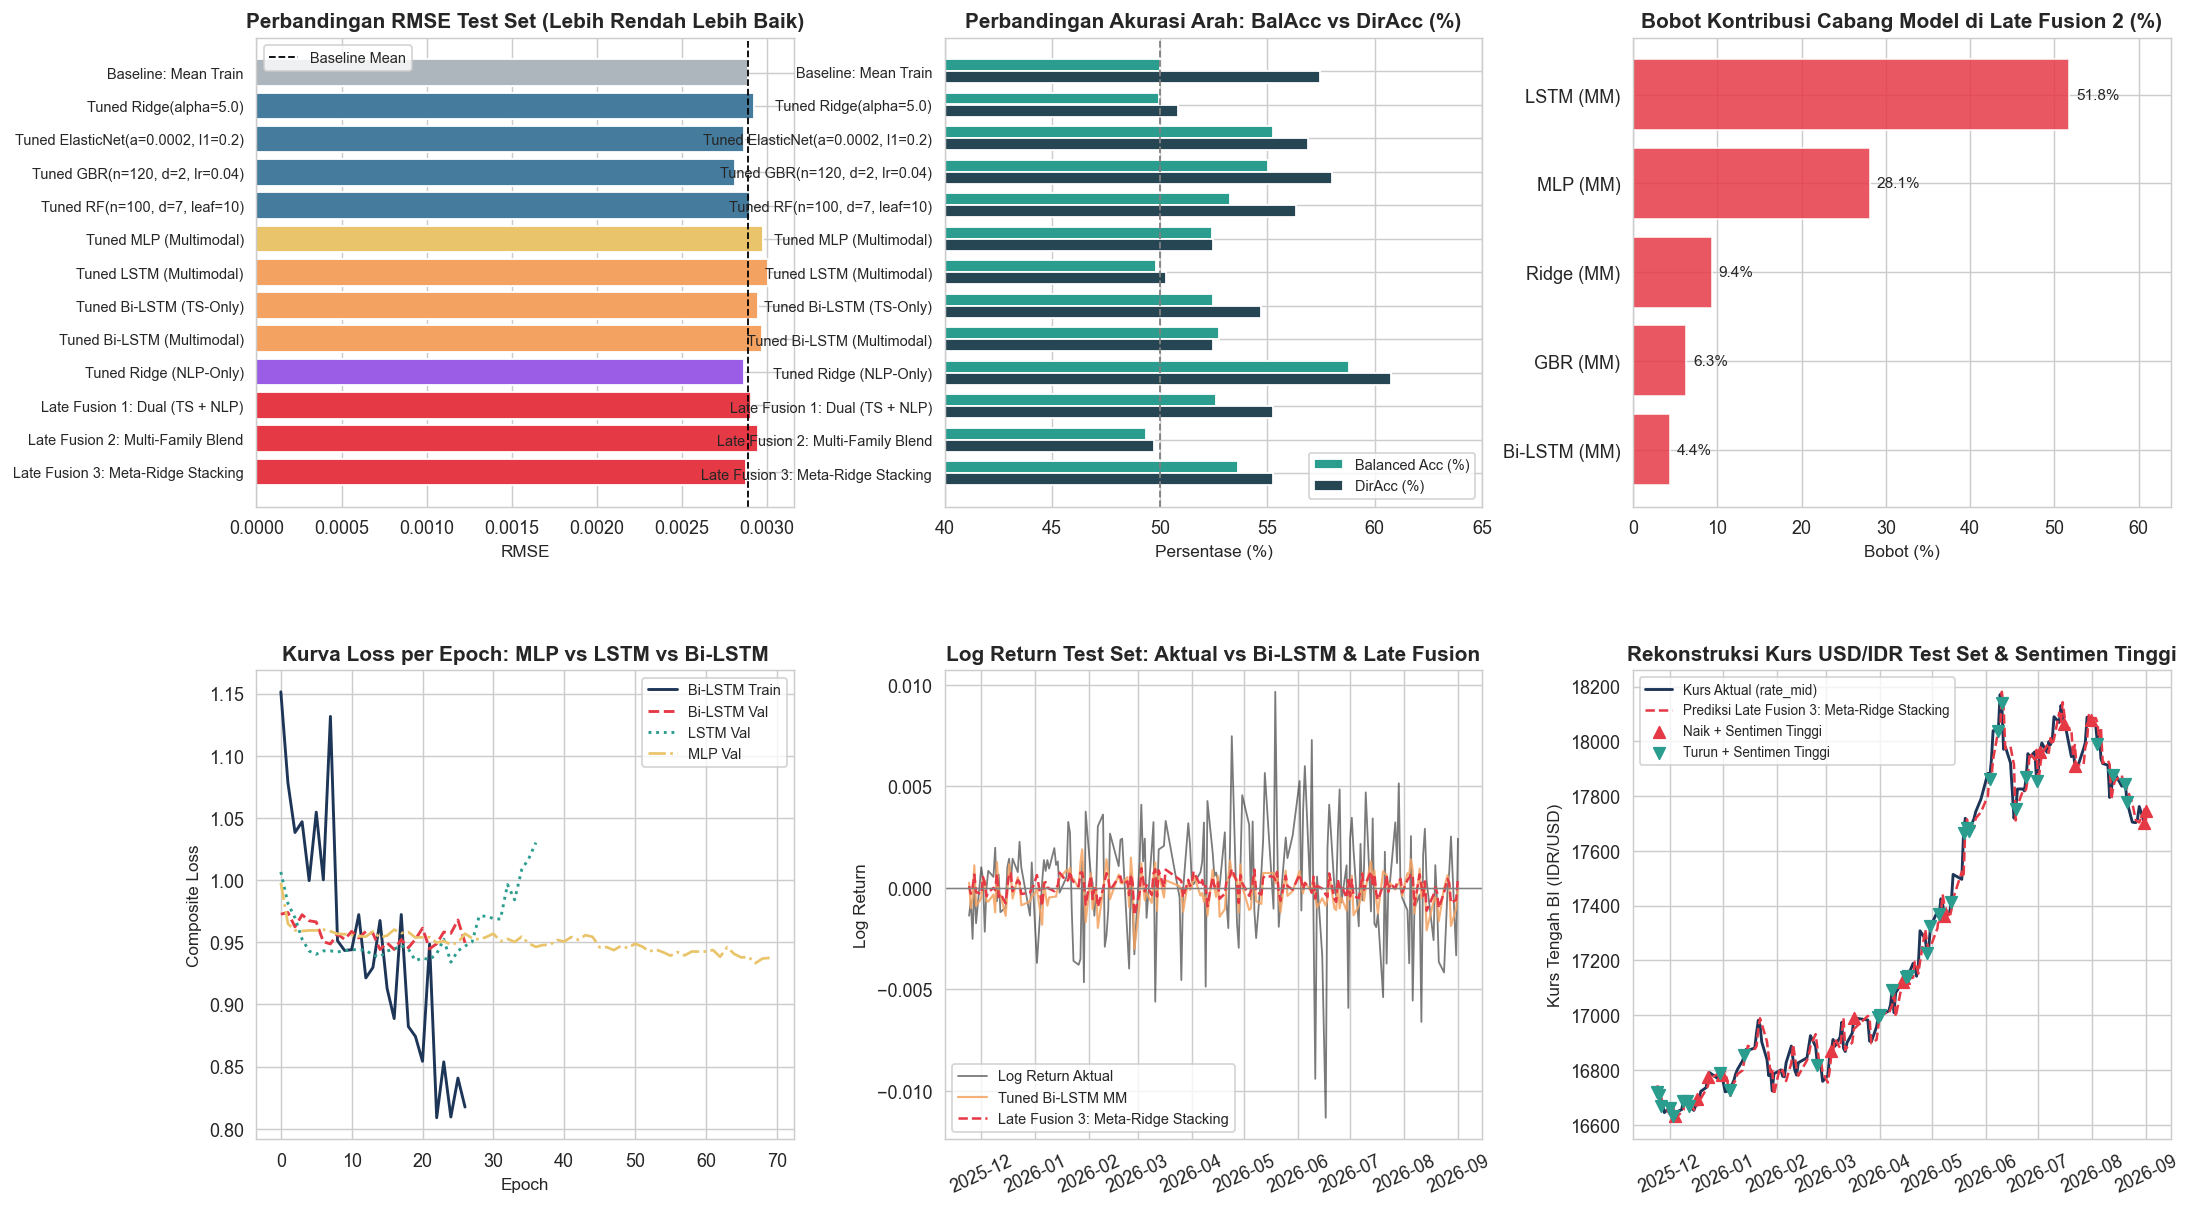

In [11]:
fig = plt.figure(figsize=(19, 11))
gs = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.28)

# 1. Perbandingan RMSE antar Keluarga Model (Test Set)
ax1 = fig.add_subplot(gs[0, 0])
plot_df = eval_test_df.drop(["Baseline: Tebak Return 0"])
fam_colors = {
    "Baseline": "#adb5bd",
    "ML Regression": "#457b9d",
    "Neural Tabular": "#e9c46a",
    "Neural Sequential": "#f4a261",
    "Expert NLP": "#9b5de5",
    "Late Fusion": "#e63946",
}
bar_cols = [fam_colors[k] for k in plot_df["Keluarga"]]
ax1.barh(plot_df.index, plot_df["RMSE"], color=bar_cols)
ax1.axvline(plot_df.loc["Baseline: Mean Train", "RMSE"], color="black", linestyle="--", lw=1, label="Baseline Mean")
ax1.invert_yaxis()
ax1.set_title("Perbandingan RMSE Test Set (Lebih Rendah Lebih Baik)")
ax1.set_xlabel("RMSE")
ax1.tick_params(axis="y", labelsize=8)
ax1.legend(fontsize=8)

# 2. Perbandingan Balanced Accuracy & DirAcc (%)
ax2 = fig.add_subplot(gs[0, 1])
y_pos = np.arange(len(plot_df))
ax2.barh(y_pos - 0.18, plot_df["BalAcc (%)"], 0.35, label="Balanced Acc (%)", color="#2a9d8f")
ax2.barh(y_pos + 0.18, plot_df["DirAcc (%)"], 0.35, label="DirAcc (%)", color="#264653")
ax2.axvline(50.0, color="gray", linestyle="--", lw=1)
ax2.set_yticks(y_pos)
ax2.set_yticklabels(plot_df.index, fontsize=8)
ax2.invert_yaxis()
ax2.set_xlim(40, max(65, plot_df[["BalAcc (%)", "DirAcc (%)"]].max().max() + 2))
ax2.set_title("Perbandingan Akurasi Arah: BalAcc vs DirAcc (%)")
ax2.set_xlabel("Persentase (%)")
ax2.legend(fontsize=8)

# 3. Bobot Kontribusi Late Fusion (Multi-Family Blend & Meta-Ridge)
ax3 = fig.add_subplot(gs[0, 2])
w_series = pd.Series(best_w_fam, index=family_keys).sort_values()
ax3.barh(w_series.index, w_series.values * 100, color="#e63946", alpha=0.85)
ax3.set_title("Bobot Kontribusi Cabang Model di Late Fusion 2 (%)")
ax3.set_xlabel("Bobot (%)")
for i, v in enumerate(w_series.values * 100):
    ax3.text(v + 0.8, i, f"{v:.1f}%", va="center", fontsize=8.5)
ax3.set_xlim(0, max(50, (w_series.max() * 100) + 12))

# 4. Kurva Training vs Validation Loss (LSTM vs Bi-LSTM Multimodal)
ax4 = fig.add_subplot(gs[1, 0])
ax4.plot(res_bilstm_mm["tr_hist"], label="Bi-LSTM Train", color="#1d3557", lw=1.6)
ax4.plot(res_bilstm_mm["va_hist"], label="Bi-LSTM Val", color="#e63946", linestyle="--", lw=1.6)
ax4.plot(res_lstm_mm["va_hist"], label="LSTM Val", color="#2a9d8f", linestyle=":", lw=1.6)
ax4.plot(res_mlp_mm["va_hist"], label="MLP Val", color="#e9c46a", linestyle="-.", lw=1.5)
ax4.set_title("Kurva Loss per Epoch: MLP vs LSTM vs Bi-LSTM")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("Composite Loss")
ax4.legend(fontsize=8)

# 5. Deret Waktu Log Return Test Set: Aktual vs Late Fusion Terbaik vs Bi-LSTM
te_mask_seq = seq_mm_plot["split"] == "test"
te_dates = seq_mm_plot["dates"][te_mask_seq]
best_lf_name = eval_test_df[eval_test_df["Keluarga"] == "Late Fusion"].sort_values(["BalAcc (%)", "RMSE"], ascending=[False, True]).index[0]
best_lf_pred = {
    "Late Fusion 1: Dual (TS + NLP)": p_lf_dual_te,
    "Late Fusion 2: Multi-Family Blend": p_lf_fam_te,
    "Late Fusion 3: Meta-Ridge Stacking": p_lf_meta_te,
}[best_lf_name]

ax5 = fig.add_subplot(gs[1, 1])
ax5.plot(te_dates, y_te_true, label="Log Return Aktual", color="#222222", alpha=0.6, lw=1.0)
ax5.plot(te_dates, res_bilstm_mm["pred_te"], label="Tuned Bi-LSTM MM", color="#f4a261", lw=1.2, alpha=0.85)
ax5.plot(te_dates, best_lf_pred, label=best_lf_name, color="#e63946", lw=1.4, linestyle="--")
ax5.axhline(0, color="gray", lw=0.8)
ax5.set_title("Log Return Test Set: Aktual vs Bi-LSTM & Late Fusion")
ax5.set_ylabel("Log Return")
ax5.tick_params(axis="x", rotation=25)
ax5.legend(fontsize=8)

# 6. Rekonstruksi Kurs USD/IDR Test Set (Late Fusion + Penanda Sentimen Tinggi)
ax6 = fig.add_subplot(gs[1, 2])
prev_rates_te = seq_mm_plot["prev_rate"][te_mask_seq]
actual_rates_te = seq_mm_plot["curr_rate"][te_mask_seq]
pred_rates_lf = prev_rates_te * np.exp(best_lf_pred)

ax6.plot(te_dates, actual_rates_te, label="Kurs Aktual (rate_mid)", color="#1d3557", lw=1.6)
ax6.plot(te_dates, pred_rates_lf, label=f"Prediksi {best_lf_name}", color="#e63946", lw=1.4, linestyle="--")

te_df_align = df_model.loc[df_model[date_col].isin(te_dates)].copy()
hi_up = te_df_align[te_df_align["flag_naik_sent_tinggi"] == 1]
hi_dn = te_df_align[te_df_align["flag_turun_sent_tinggi"] == 1]
ax6.scatter(hi_up[date_col], hi_up["rate_mid"], marker="^", s=40, color="#e63946", zorder=5, label="Naik + Sentimen Tinggi")
ax6.scatter(hi_dn[date_col], hi_dn["rate_mid"], marker="v", s=40, color="#2a9d8f", zorder=5, label="Turun + Sentimen Tinggi")

ax6.set_title("Rekonstruksi Kurs USD/IDR Test Set & Sentimen Tinggi")
ax6.set_ylabel("Kurs Tengah BI (IDR/USD)")
ax6.tick_params(axis="x", rotation=25)
ax6.legend(fontsize=7.5)

plt.tight_layout()
plt.show()


## 12. Verifikasi Kepatuhan Anti-Leakage & Ringkasan Pipeline

- **Split di Awal**: Pembagian kronologis `70% / 15% / 15%` dilakukan pada langkah 2 sebelum pemodelan atau transformasi apa pun.
- **Frozen Pretrained Models**: `bert-base-uncased` (judul), `ProsusAI/finbert` (sentimen & kecenderungan polaritas), dan `all-MiniLM-L6-v2` (BERTopic) seluruhnya dibekukan (`requires_grad=False`) tanpa *fine-tuning* pada Val/Test.
- **Fit Murni di Train & Tuning Murni di Validation**: PCA judul BERT, BERTopic, PCA & UMAP 2D BERTopic, `StandardScaler`, kuantil sentimen tinggi (`HIGH_SENT_THRES`), Classifier Stage 1 (dengan **5-Fold OOF** di Train), ML Regression (`Ridge`, `ElasticNet`, `GBR`, `RF`), `MLP`, `LSTM`, `Bi-LSTM`, serta bobot **Late Fusion** semuanya di-*fit* tanpa pernah melihat Test Set.
